<a href="https://colab.research.google.com/github/2952342H/Effect-of-Electrode-Density-on-Rate-Performance-in-Li-rich-Cathodes/blob/main/BATCH_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload ONE latest FULL Excel export per cell (up to eight cells).
Names may be 001.01.xlsx or the original long tester filenames.


Saving 002.02.xlsx to 002.02.xlsx
Saving 002.03.xlsx to 002.03.xlsx
Saving 003.02.xlsx to 003.02.xlsx
Saving 002.01.xlsx to 002.01.xlsx
Saving 003.01.xlsx to 003.01.xlsx
Saving 001.01.xlsx to 001.01.xlsx
Saving 001.02.xlsx to 001.02.xlsx
Saving 001.03.xlsx to 001.03.xlsx
Read 002.02: 2026-10-26 14:07:33
Read 002.03: 2026-10-26 14:07:30
Read 003.02: 2026-10-26 14:07:37
Read 002.01: 2026-10-26 14:07:36
Read 003.01: 2026-10-26 14:07:35
Read 001.01: 2026-10-26 14:07:23
Read 001.02: 2026-10-26 14:07:25
Read 001.03: 2026-10-26 14:07:37
Record capacities, step end values and durations agree with the exported summaries within rounding tolerances.


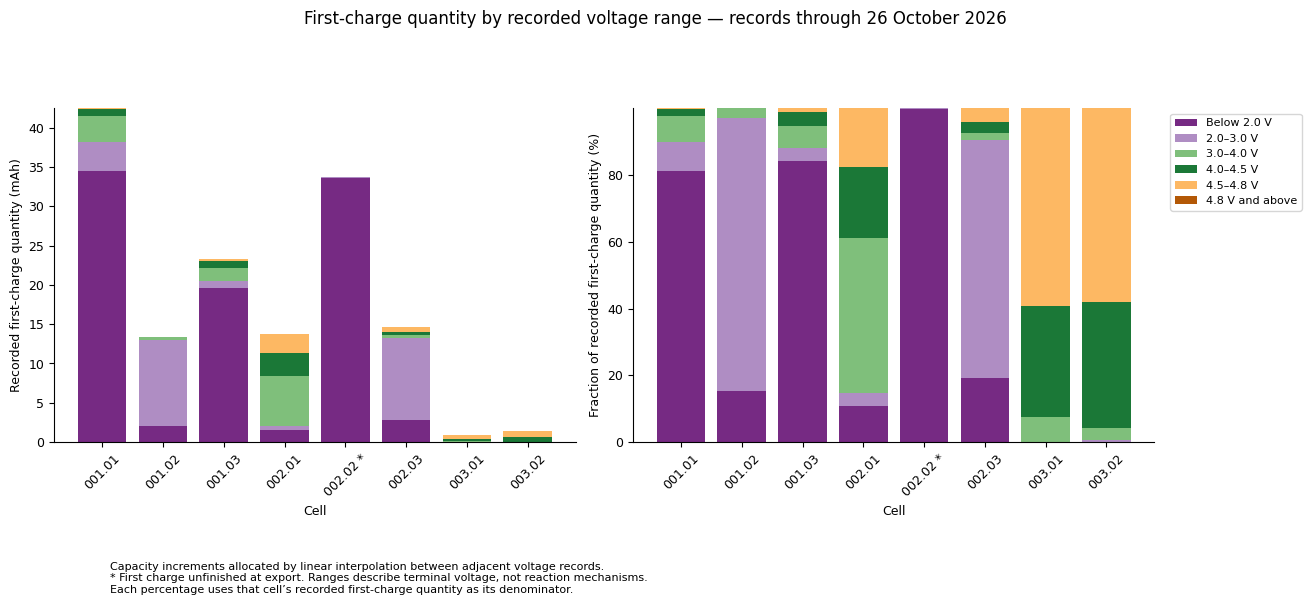

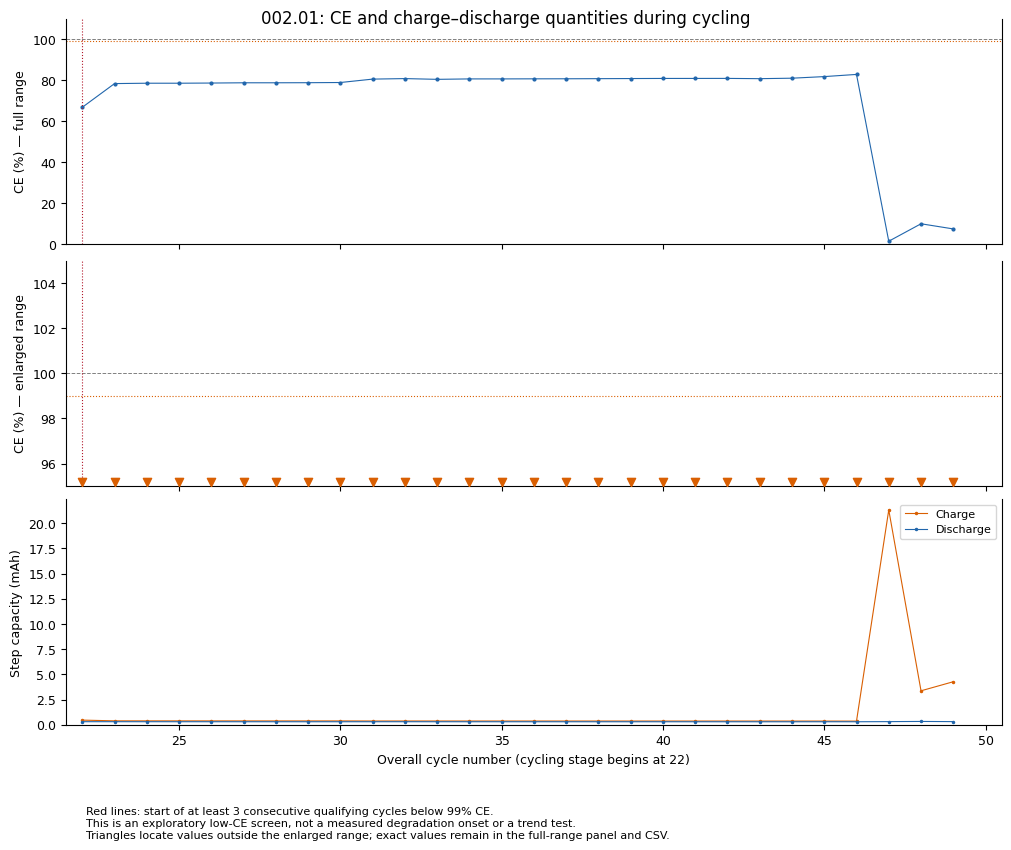

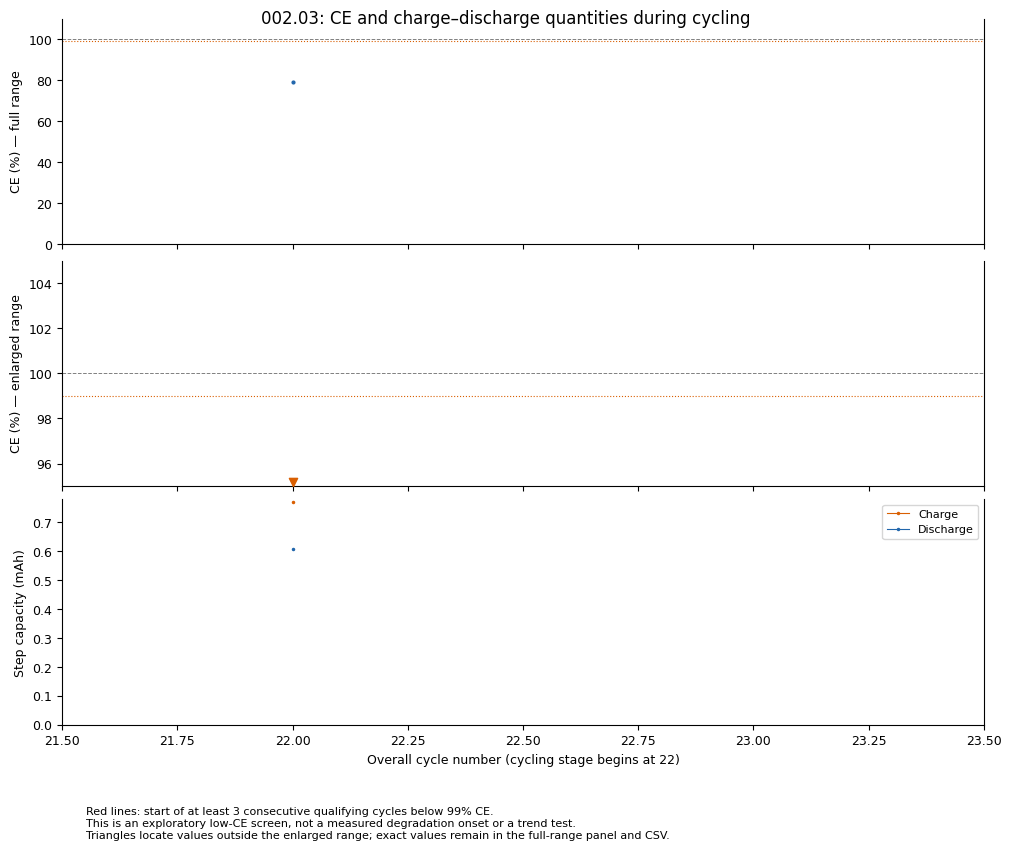

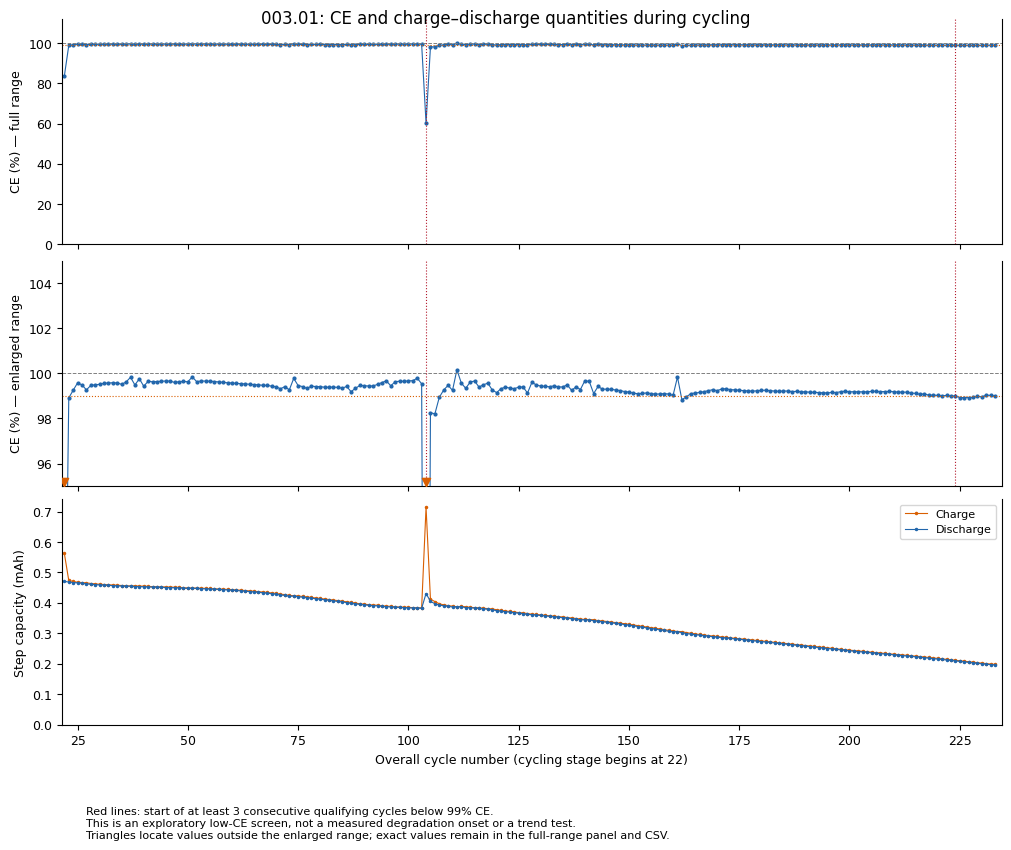

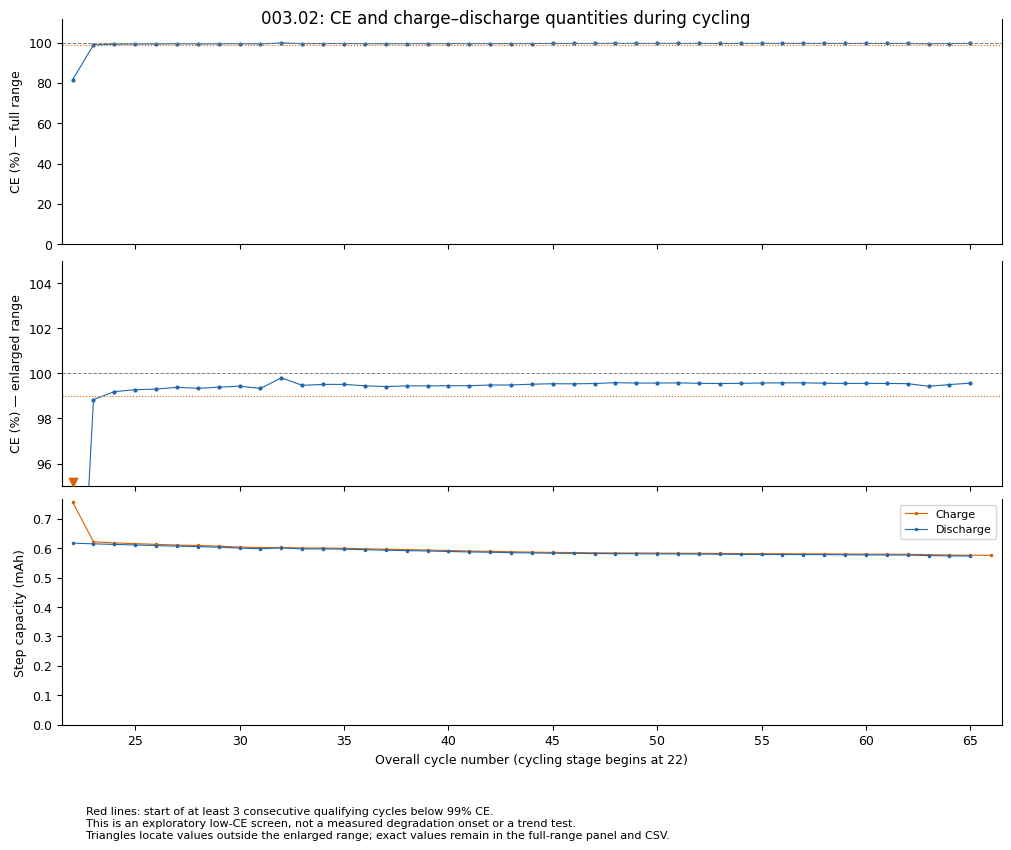

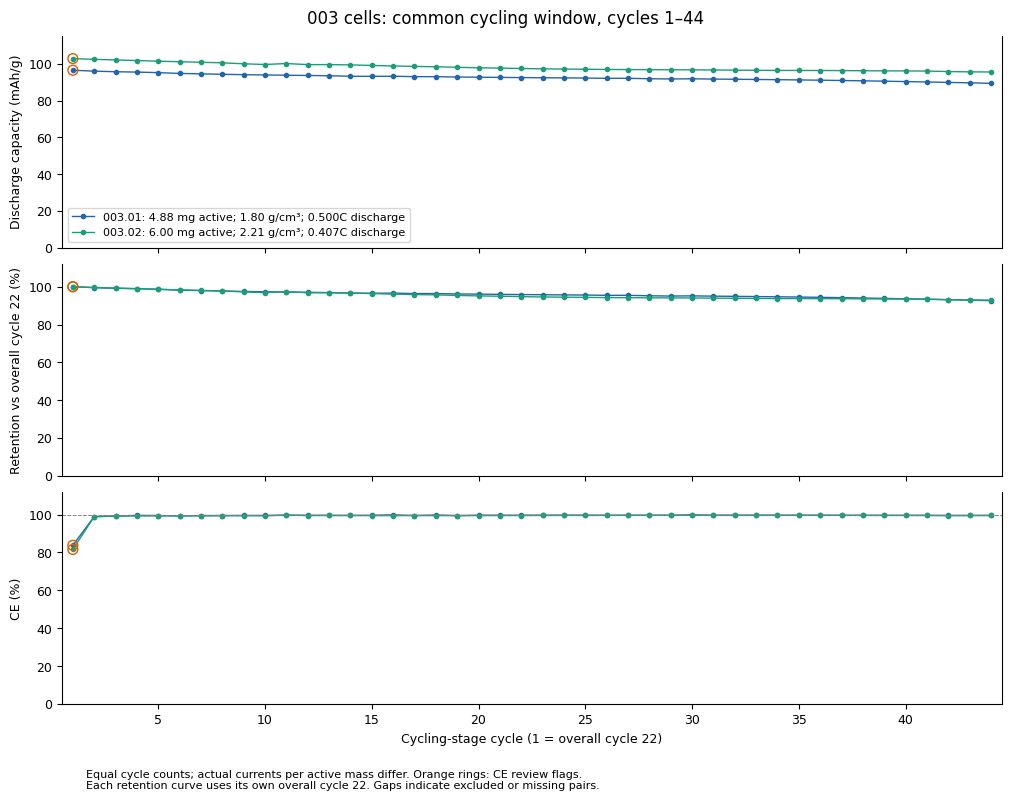

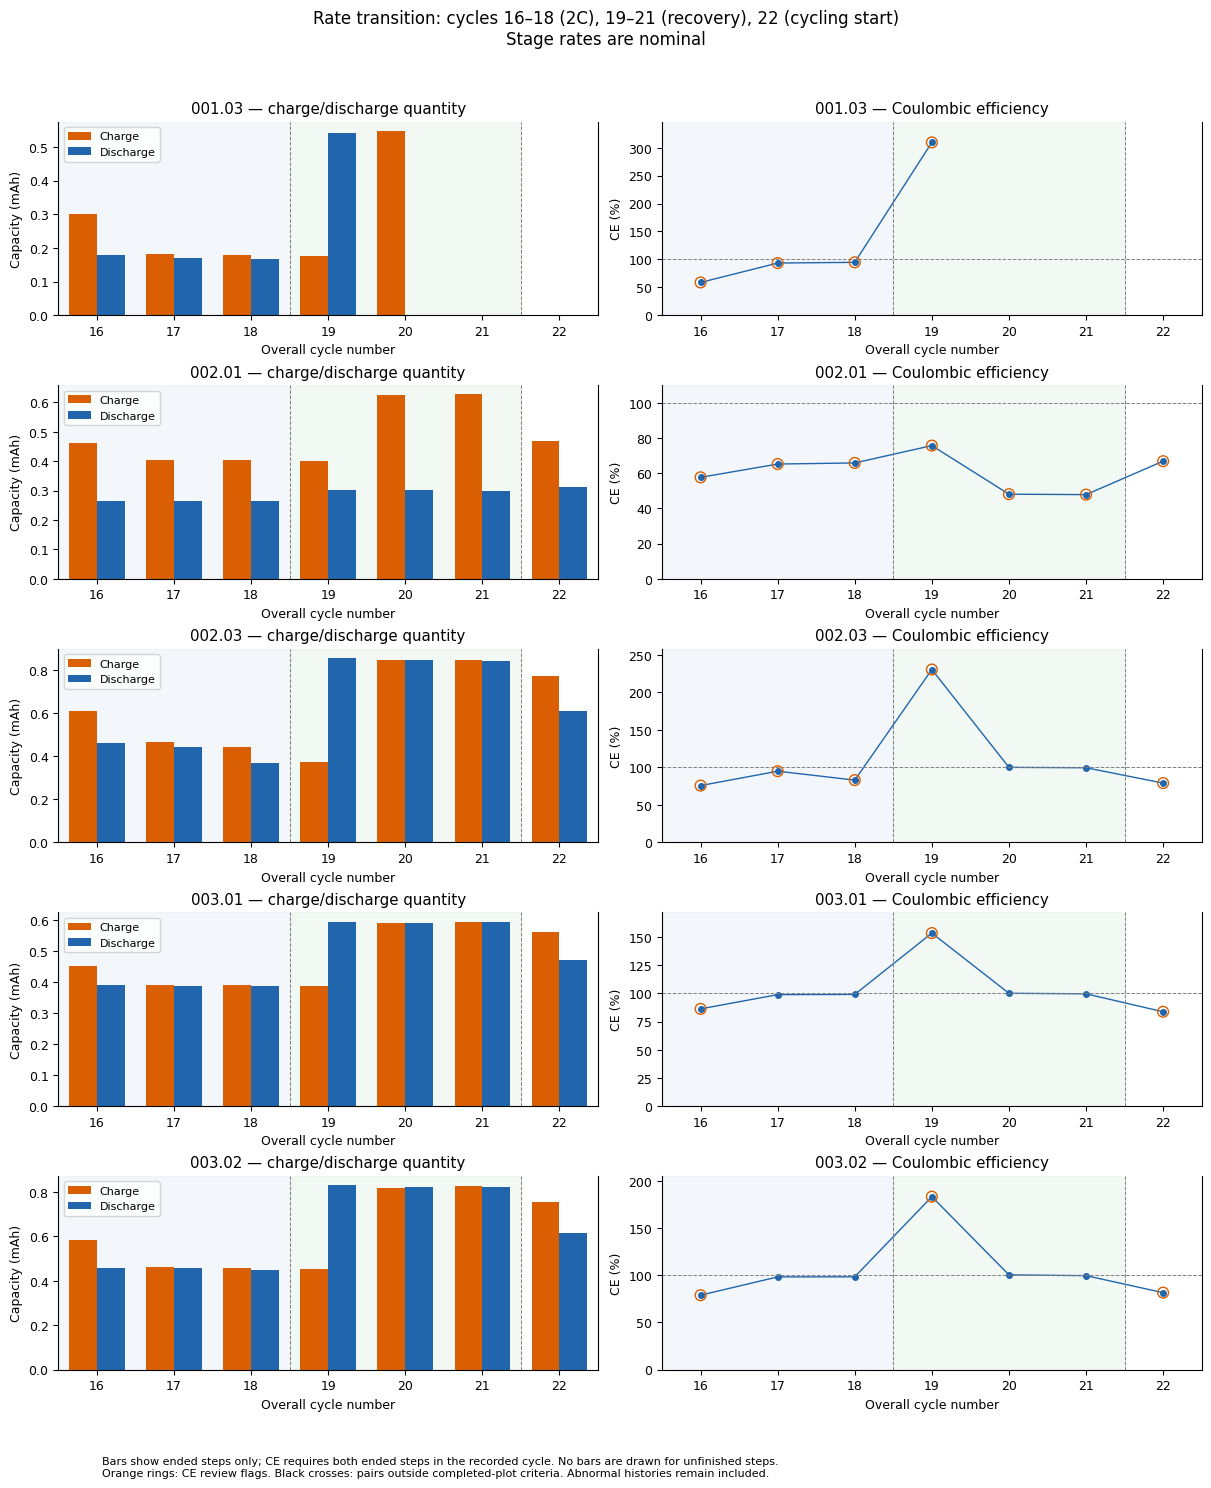

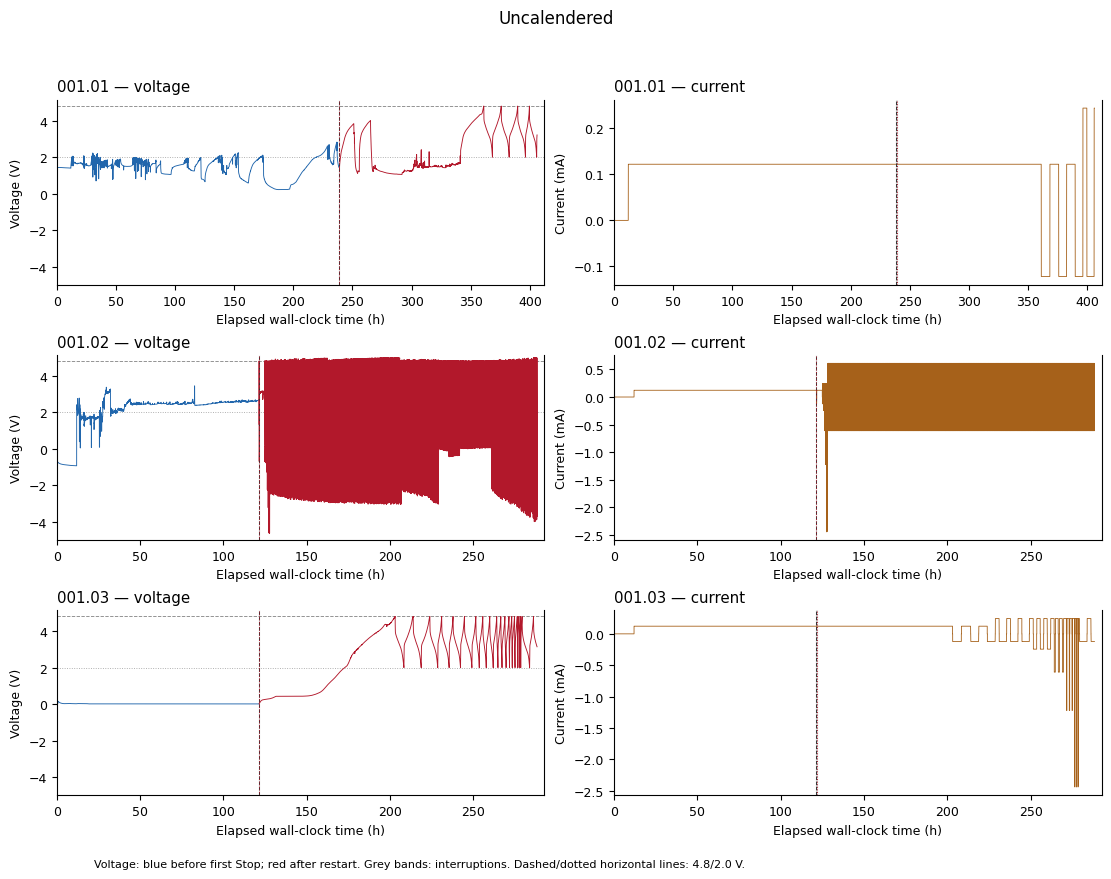

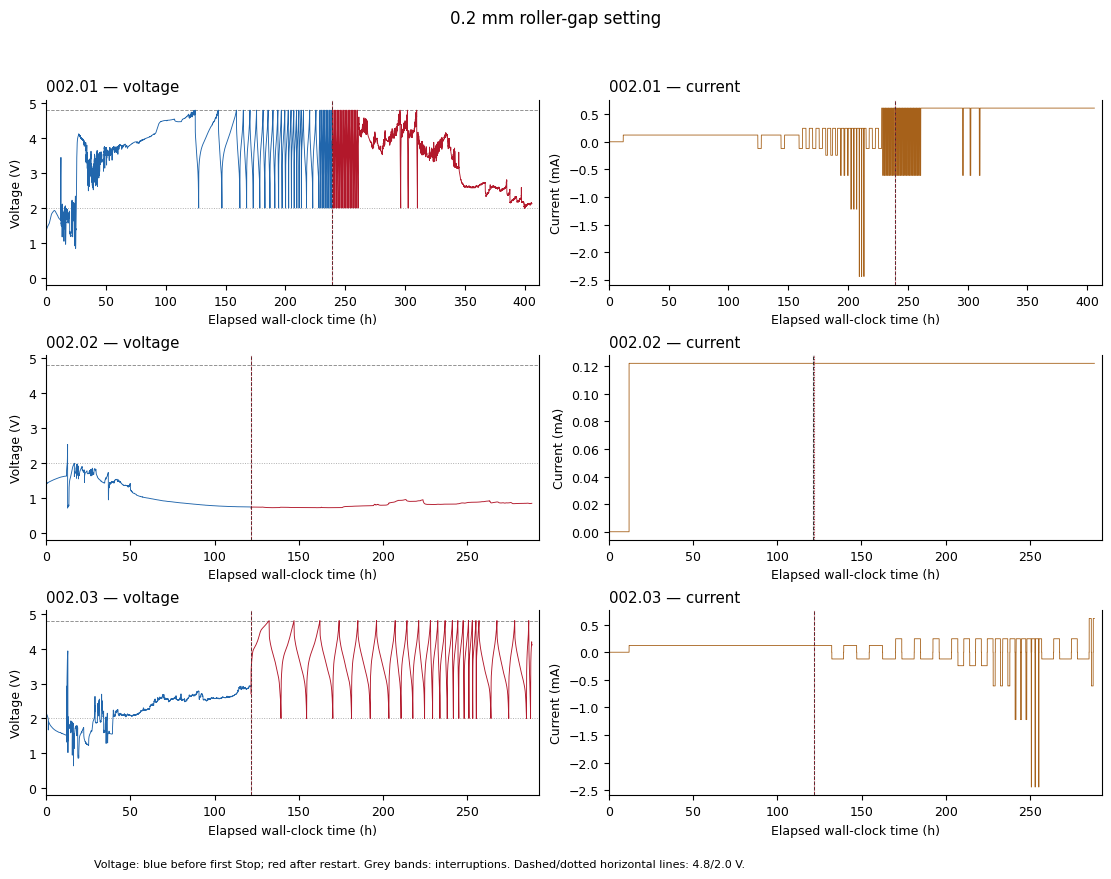

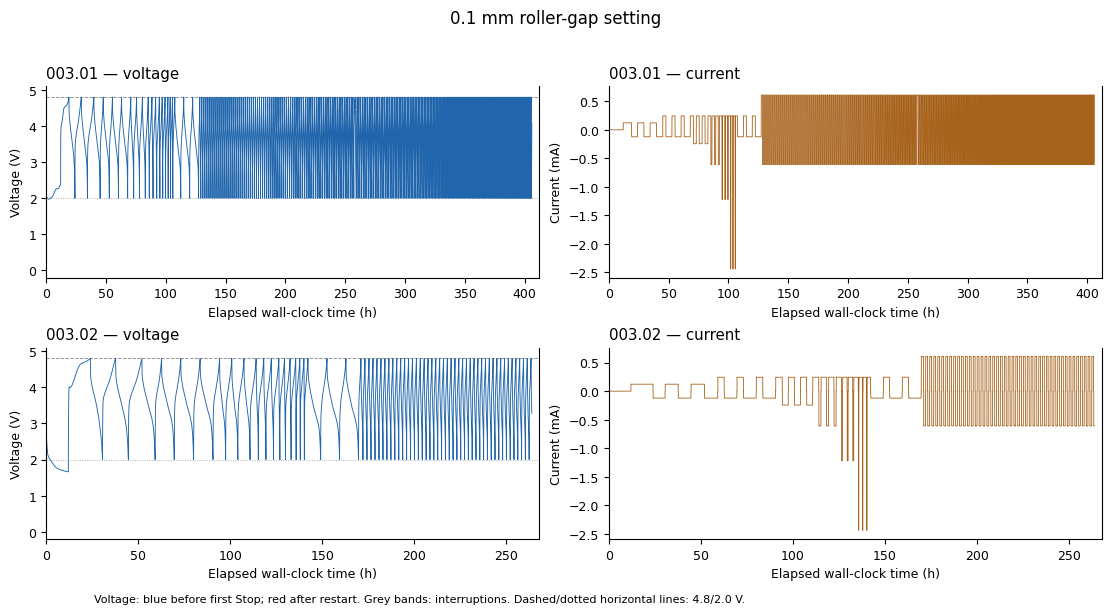

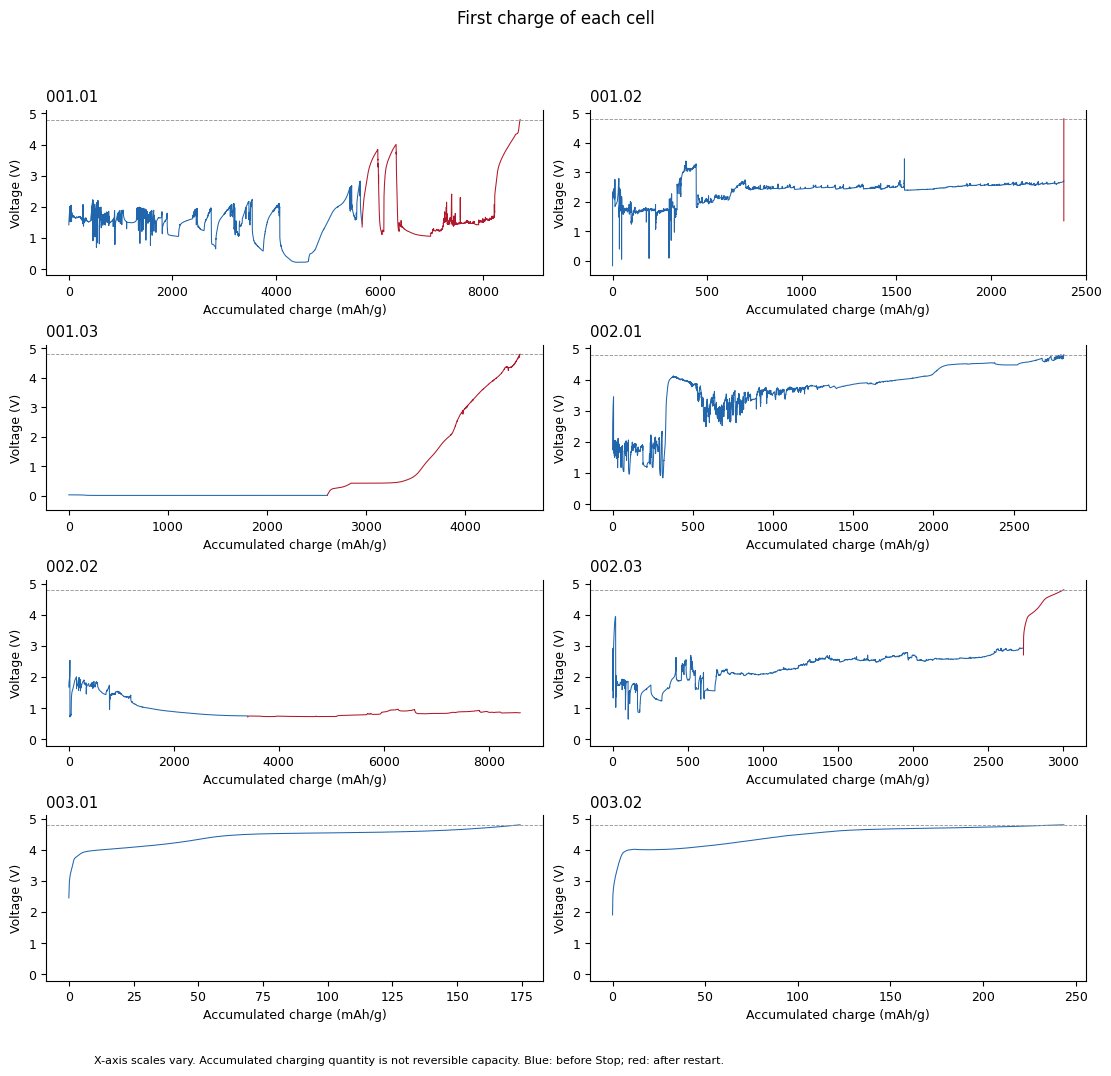

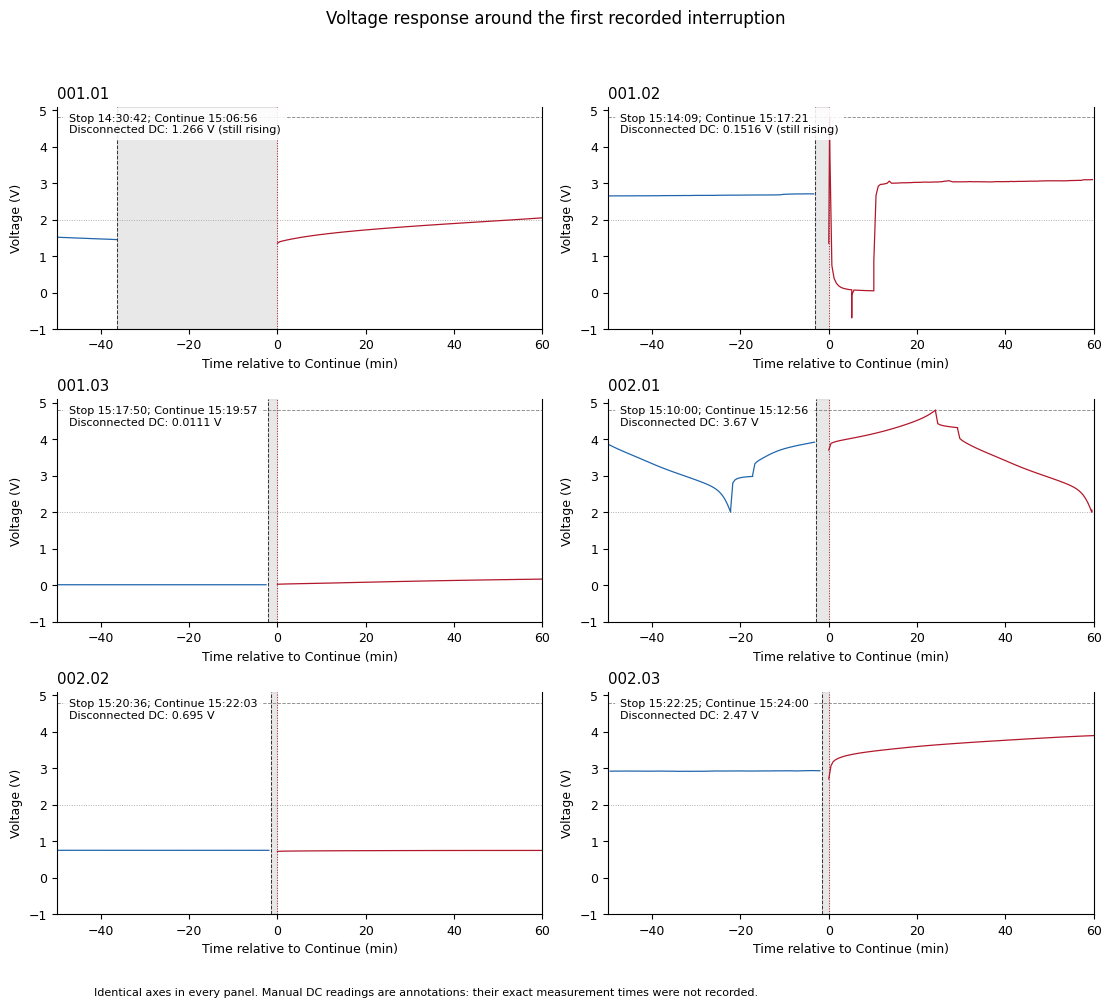

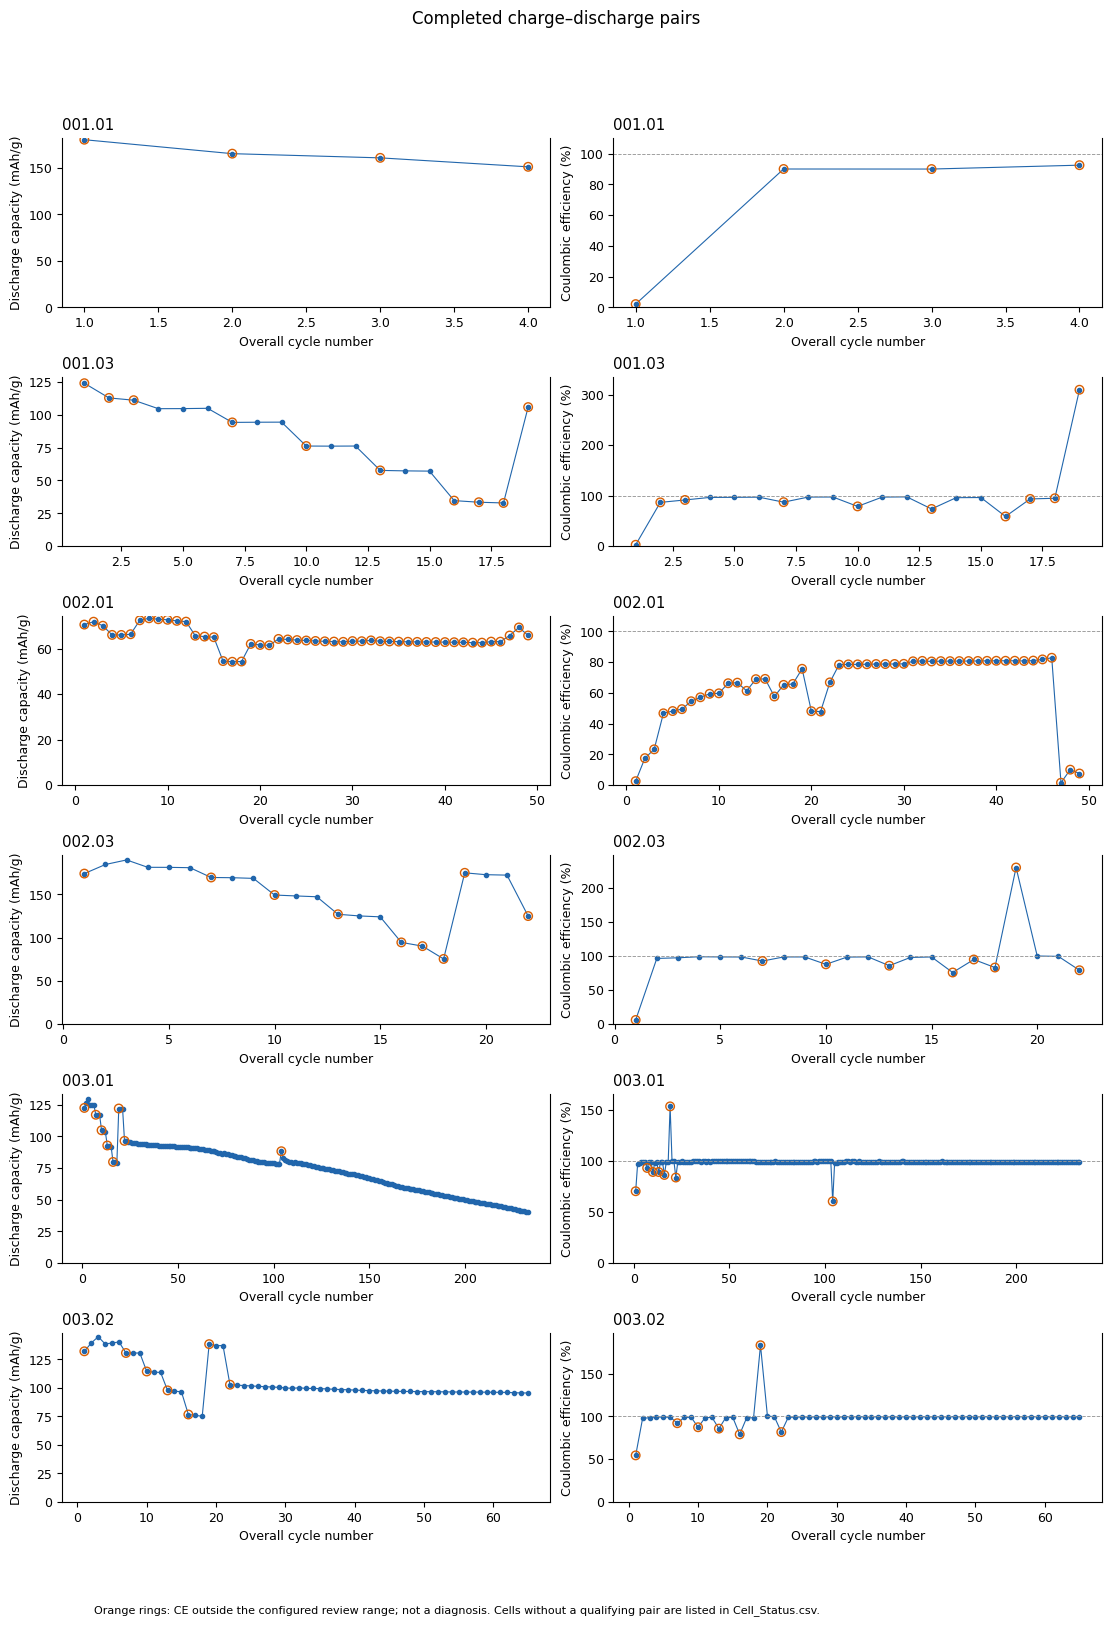

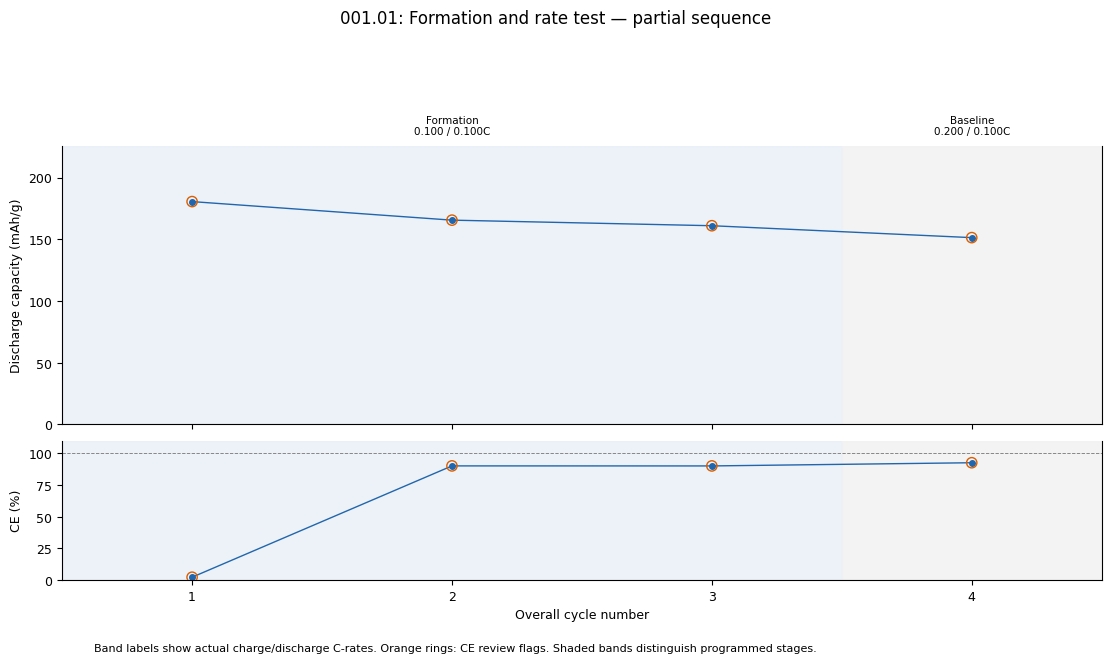

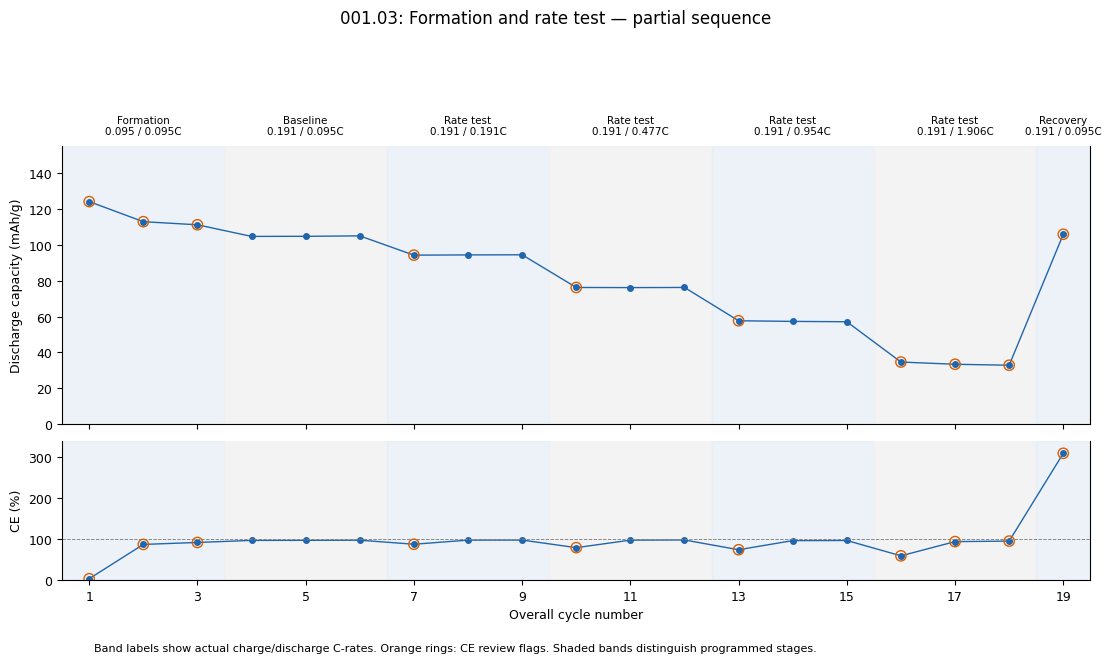

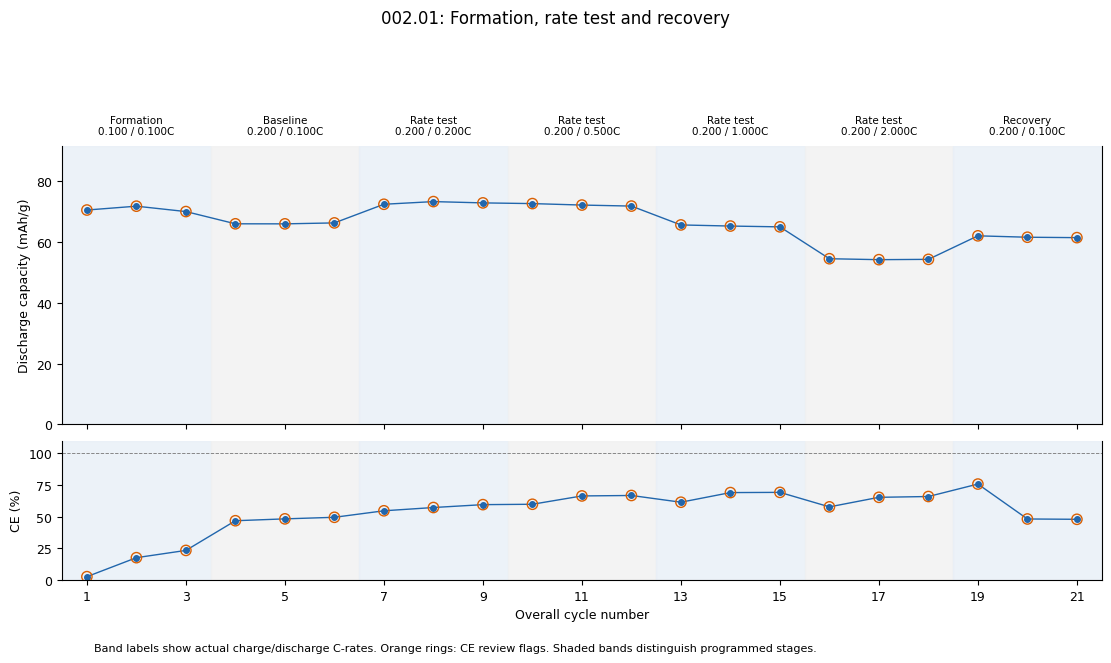

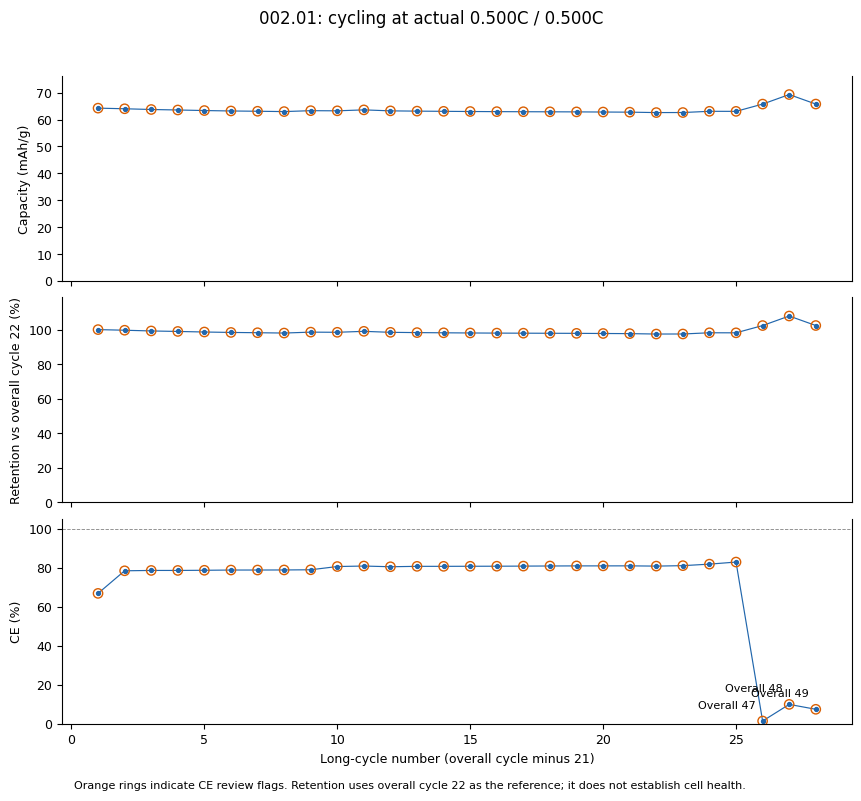

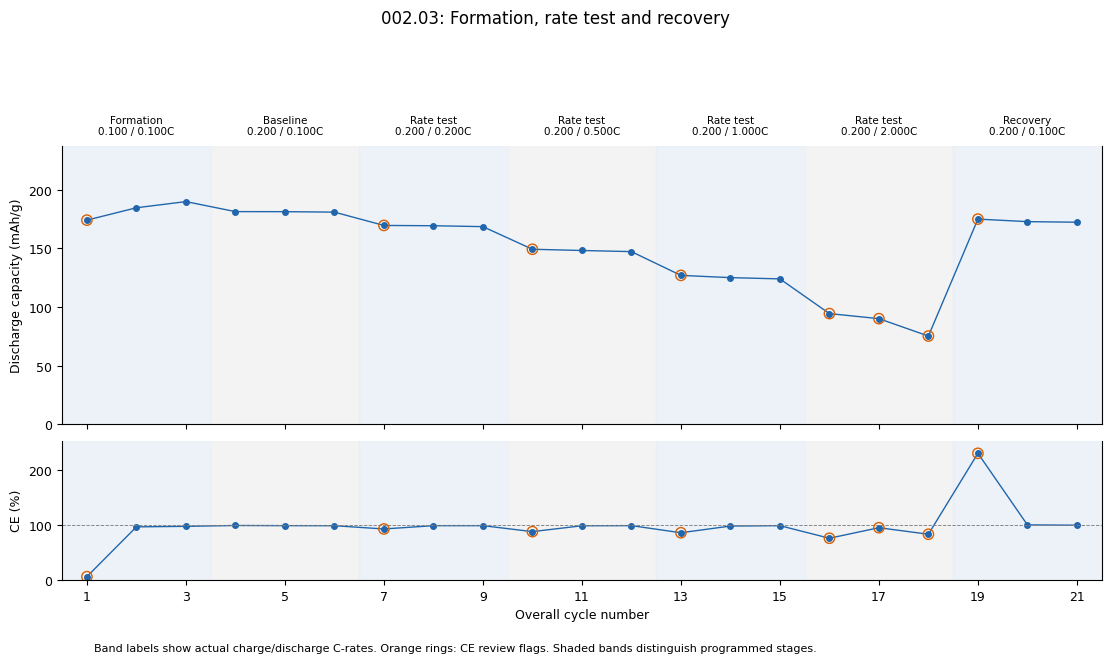

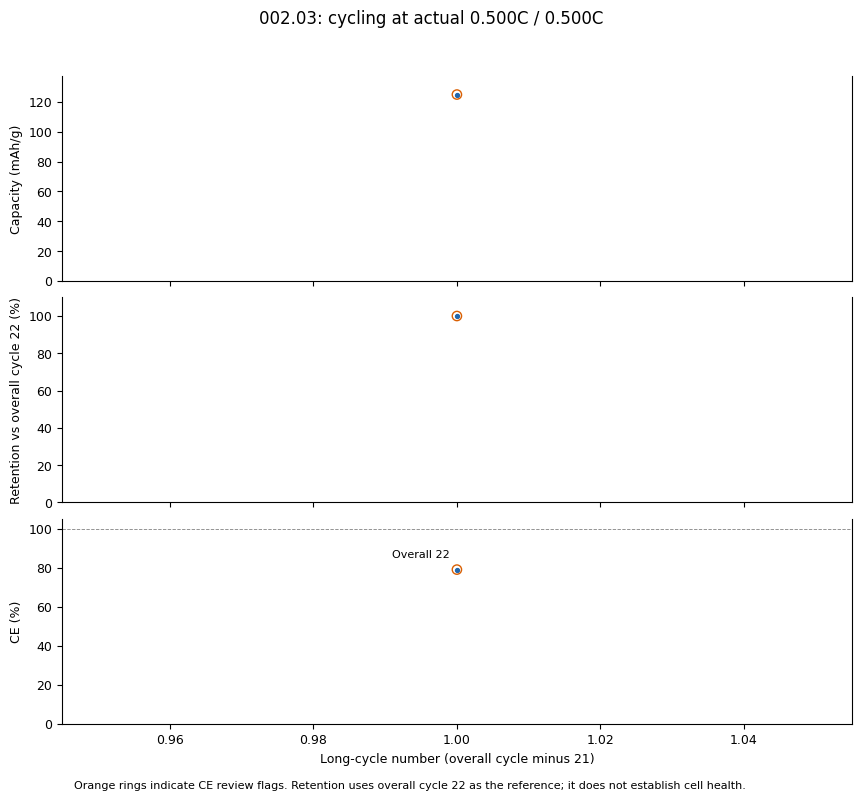

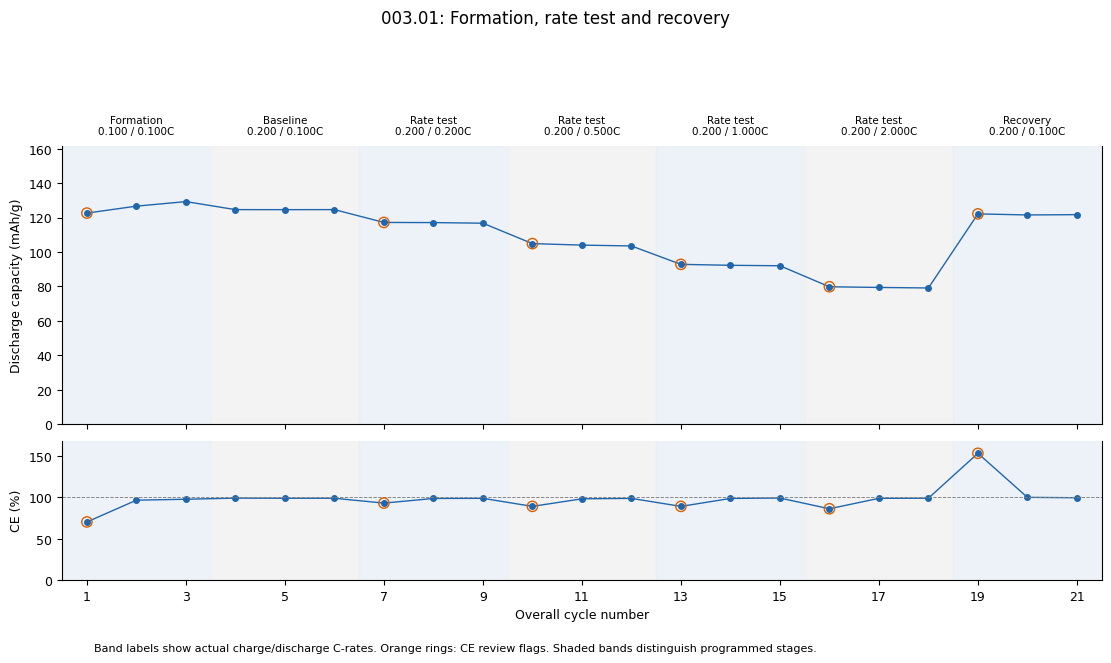

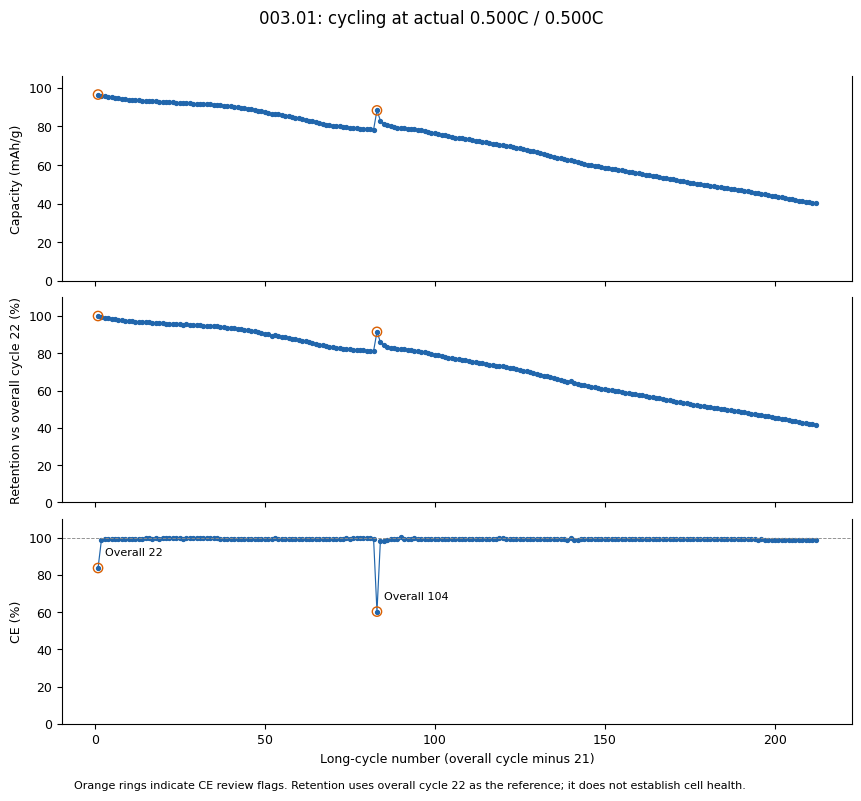

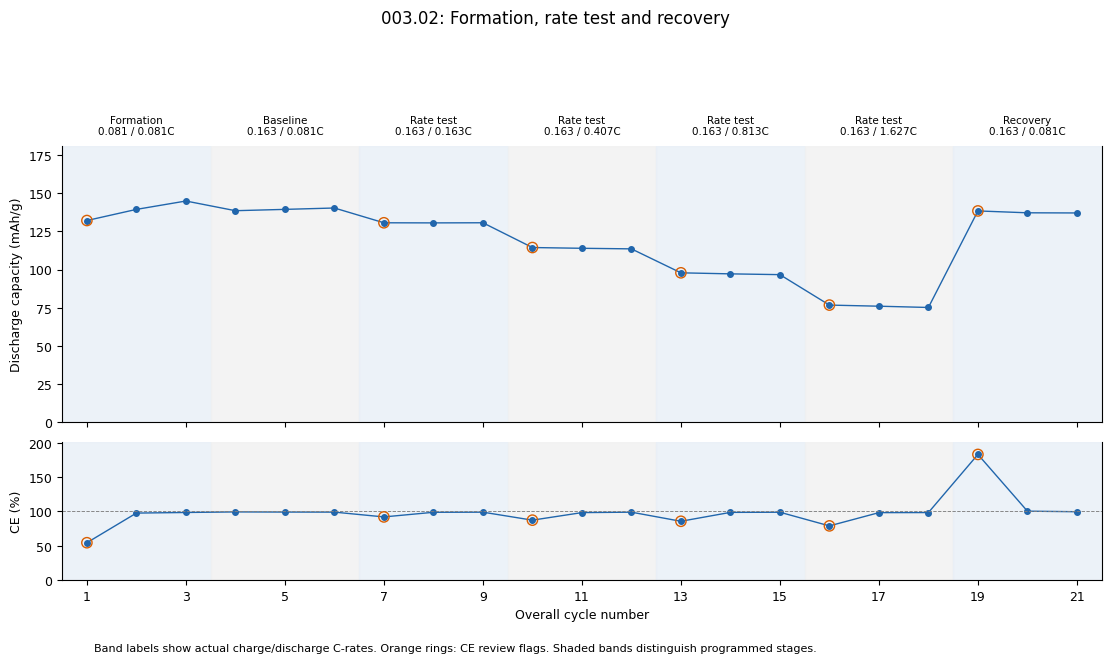

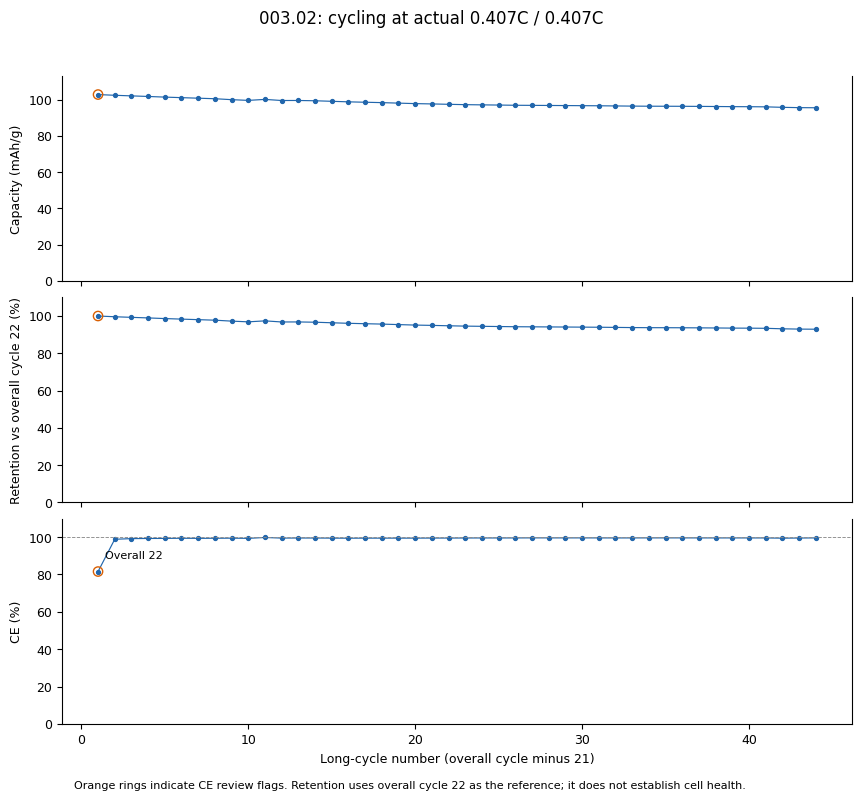

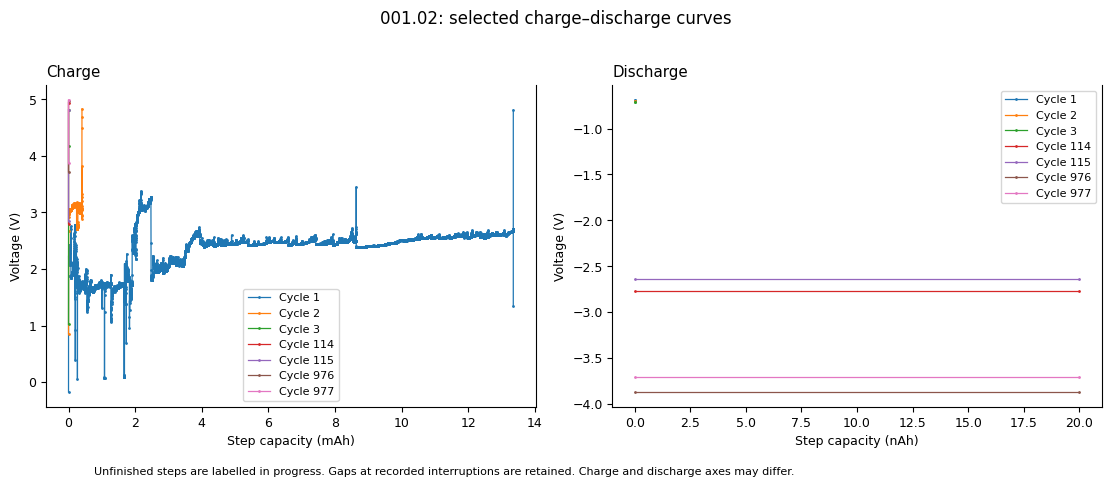

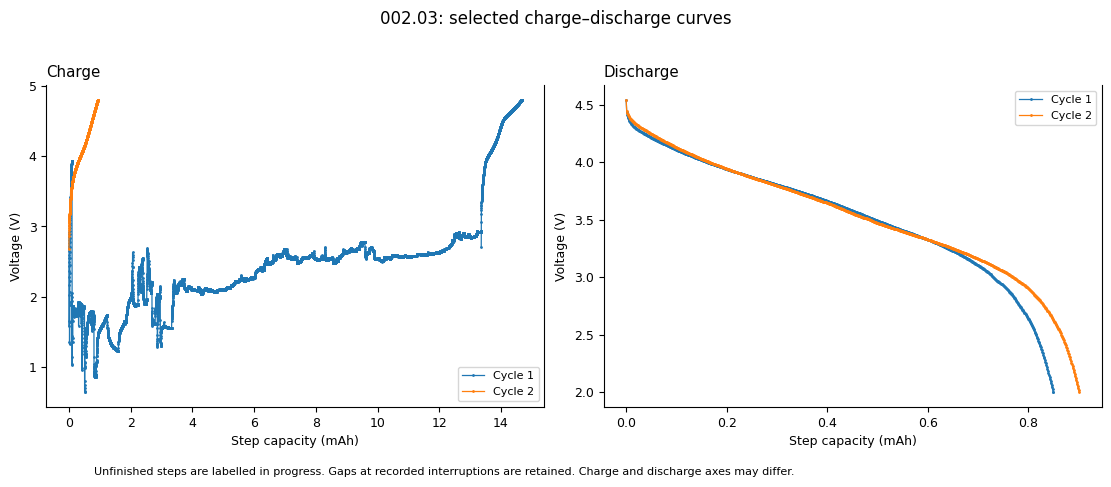

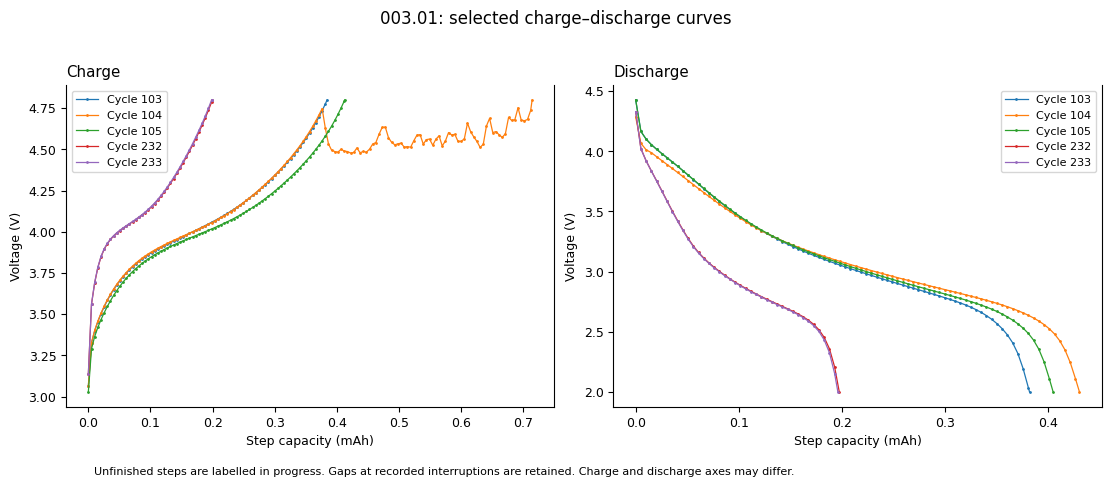

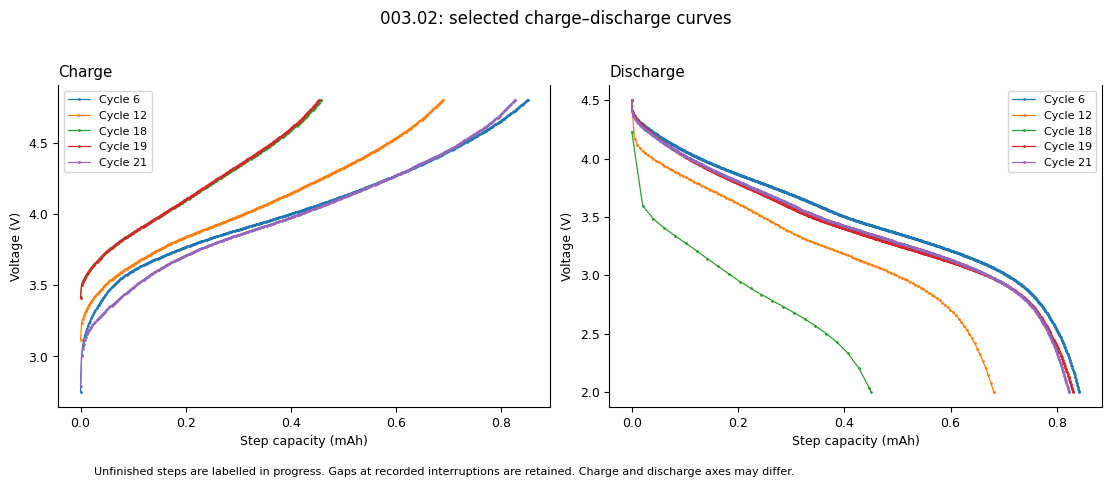

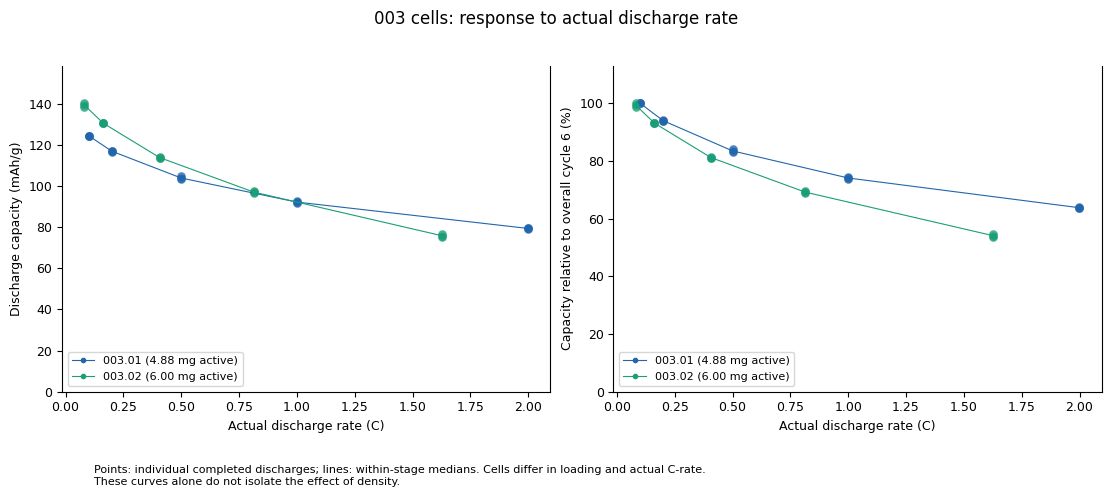

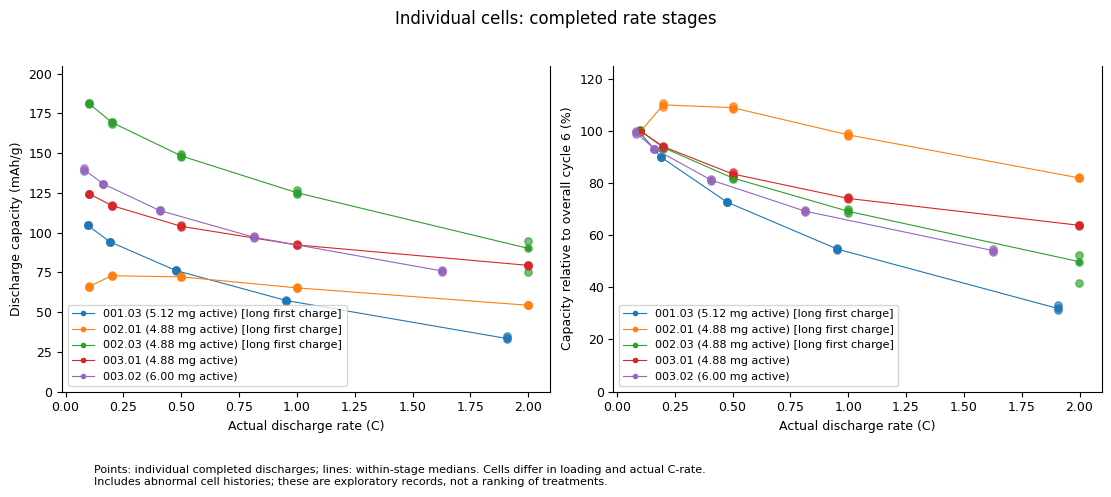

  cell  current_cycle current_step  last_voltage_V  cycles_in_cycle_plot  last_plotted_CE_percent
001.01              5       CC Chg          3.2174                     4                92.536977
001.02            977         Rest         -0.0056                     0                      NaN
001.03             20      CC DChg          3.1418                    19               309.586928
002.01             50       CC Chg          2.1301                    49                 7.506299
002.02              1       CC Chg          0.8544                     0                      NaN
002.03             23       CC Chg          4.1083                    22                79.011946
003.01            234       CC Chg          4.0649                   233                99.001563
003.02             66      CC DChg          3.2841                    65                99.569257

Plot inclusion checks completion and non-negligible duration/capacity, not cell health.
Review flags are retained in 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import argparse
import importlib.util
import re
import shutil
import tempfile
import warnings
from io import BytesIO
from pathlib import Path

if importlib.util.find_spec("openpyxl") is None:
    raise ImportError("Install openpyxl first: %pip install openpyxl")

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd

warnings.filterwarnings(
    "ignore",
    message="Workbook contains no default style"
)

# Masses exclude foil, SP and PVDF. Thicknesses exclude foil.
CELL_INFO = {
    "001.01": ("Uncalendered", 4.88, 41.0, "1-2"),
    "001.02": ("Uncalendered", 5.60, 41.0, "2-2"),
    "001.03": ("Uncalendered", 5.12, 41.0, "2-3"),
    "002.01": ("0.2 mm roller-gap setting", 4.88, 34.0, "1-3"),
    "002.02": ("0.2 mm roller-gap setting", 3.92, 34.0, "4-3"),
    "002.03": ("0.2 mm roller-gap setting", 4.88, 34.0, "4-4"),
    "003.01": ("0.1 mm roller-gap setting", 4.88, 30.0, "1-4"),
    "003.02": ("0.1 mm roller-gap setting", 6.00, 30.0, "2-4"),
}

SPECIFIC_CAPACITY_REFERENCE = 250.0
UPPER_CUTOFF = 4.8
LOWER_CUTOFF = 2.0
VOLTAGE_TOLERANCE = 0.01
MIN_STEP_SECONDS = 1.0
MIN_CAPACITY_MAH = 0.0001

# Review thresholds do not diagnose faults or degradation onset.
LONG_CHARGE_H = 48.0
CE_REVIEW_LOW = 95.0
CE_REVIEW_HIGH = 105.0
CE_DETAIL_LOWER = 95.0
CE_DETAIL_UPPER = 105.0
CE_LOW_LEVEL = 99.0
CE_LOW_RUN_LENGTH = 3

MANUAL_DC = {
    "001.01": (1.266, "Still increasing within the first minute"),
    "001.02": (0.1516, "Still increasing within the first minute"),
    "001.03": (0.0111, "Display was not changing when recorded"),
    "002.01": (3.67, "Display was not changing when recorded"),
    "002.02": (0.695, "Display was not changing when recorded"),
    "002.03": (2.47, "Display was not changing when recorded"),
}

OBSERVATION_DATE = pd.Timestamp("2026-10-19").date()

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.spines.top": False,
    "savefig.dpi": 300,
})


def hours(value):
    if value is None:
        return np.nan
    if hasattr(value, "total_seconds"):
        return value.total_seconds() / 3600
    if hasattr(value, "hour"):
        return value.hour + value.minute / 60 + value.second / 3600
    if isinstance(value, (int, float)):
        return float(value) * 24
    try:
        h, m, s = map(float, str(value).split(":"))
        return h + m / 60 + s / 3600
    except (ValueError, TypeError):
        return np.nan


def stage(cycle):
    stages = [
        (3, "Formation", .1, .1),
        (6, "Baseline", .2, .1),
        (9, "Rate 0.2C", .2, .2),
        (12, "Rate 0.5C", .2, .5),
        (15, "Rate 1C", .2, 1.),
        (18, "Rate 2C", .2, 2.),
        (21, "Recovery", .2, .1),
    ]
    for end, name, charge_rate, discharge_rate in stages:
        if cycle <= end:
            return name, charge_rate, discharge_rate
    return "Long cycling", .5, .5


def read_table(workbook, name):
    sheet = workbook[name]
    sheet.reset_dimensions()
    rows = sheet.iter_rows(values_only=True)
    header = next(rows)
    names = [
        str(v).strip() if v is not None else f"blank_{i}"
        for i, v in enumerate(header)
    ]
    return pd.DataFrame(
        (
            list(row)[:len(names)]
            + [None] * max(0, len(names) - len(row))
            for row in rows
        ),
        columns=names,
    ).dropna(how="all")


def read_export(content, filename):
    workbook = openpyxl.load_workbook(
        BytesIO(content),
        read_only=True,
        data_only=True,
    )
    try:
        required = {"unit", "test", "cycle", "step", "record", "log"}
        if not required.issubset(workbook.sheetnames):
            raise ValueError(
                f"{filename}: upload the full export with unit, test, "
                "cycle, step, record and log worksheets."
            )

        raw = {}
        for name in ["unit", "test"]:
            sheet = workbook[name]
            sheet.reset_dimensions()
            raw[name] = list(sheet.values)

        device = next(
            (row for row in raw["unit"] if row and row[0] == "device"),
            None,
        )
        if device is None or len(device) < 4:
            raise ValueError(f"{filename}: channel metadata missing.")

        channel = f"{int(device[2])}-{int(device[3])}"
        matches = [
            cell for cell, info in CELL_INFO.items()
            if info[3] == channel
        ]
        if len(matches) != 1:
            raise ValueError(f"{filename}: unknown channel {channel}.")

        cell = matches[0]
        named = re.search(
            r"(?<!\d)(00[123])[._](0[123])(?!\d)",
            Path(filename).stem,
        )
        if named and f"{named.group(1)}.{named.group(2)}" != cell:
            raise ValueError(
                f"{filename}: filename and channel identify "
                f"different cells ({cell})."
            )

        mass_row = next(
            (
                row for row in raw["test"]
                if row and str(row[0]).strip() == "Active material"
            ),
            None,
        )
        mass_text = (
            str(mass_row[2])
            if mass_row and len(mass_row) > 2
            else ""
        )
        match = re.search(
            r"([0-9]+(?:\.[0-9]+)?)\s*mg",
            mass_text,
            re.I,
        )
        entered_mass = float(match.group(1)) if match else np.nan

        condition, confirmed_mass, thickness, _ = CELL_INFO[cell]
        mass = (
            confirmed_mass
            if confirmed_mass is not None
            else entered_mass
        )
        if not np.isfinite(mass) or mass <= 0:
            raise ValueError(
                f"{cell}: active mass is missing; "
                "enter a verified value in CELL_INFO."
            )

        info = {
            "cell": cell,
            "filename": filename,
            "channel": channel,
            "condition": condition,
            "active_mass_mg": mass,
            "entered_active_mass_mg": entered_mass,
            "mass_verified": confirmed_mass is not None,
            "mass_source": (
                "User measurement record"
                if confirmed_mass is not None
                else "Tester entry; physical active mass needs confirmation"
            ),
            "mass_metadata_mismatch": bool(
                np.isfinite(entered_mass)
                and abs(mass - entered_mass) > .001
            ),
            "coating_thickness_um": thickness,
        }

        exported_cycles = read_table(workbook, "cycle")

        steps = read_table(workbook, "step").rename(columns={
            "Cycle Index": "cycle",
            "Step Index": "step_index",
            "Step Number": "step_number",
            "Step Type": "step_type",
            "Step Time": "step_time",
            "Oneset Date": "start_date",
            "End Date": "end_date",
            "Capacity(mAh)": "capacity_mAh",
            "Energy(Wh)": "energy_Wh",
            "Oneset Volt.(V)": "start_voltage_V",
            "End Voltage(V)": "end_voltage_V",
        })

        records = read_table(workbook, "record").rename(columns={
            "DataPoint": "data_point",
            "Step Type": "step_type",
            "Time": "step_time",
            "Total Time": "total_time",
            "Current(mA)": "current_mA",
            "Voltage(V)": "voltage_V",
            "Capacity(mAh)": "capacity_mAh",
            "Energy(Wh)": "energy_Wh",
            "Date": "date",
        })

        logs = read_table(workbook, "log").rename(columns={
            "DataPoint": "data_point",
            "Time": "date",
            "Event": "event",
        })

    finally:
        workbook.close()

    records["date"] = pd.to_datetime(records["date"], errors="raise")
    logs["date"] = pd.to_datetime(logs["date"], errors="raise")

    for column in ["start_date", "end_date"]:
        steps[column] = pd.to_datetime(
            steps[column],
            errors="raise",
        )

    records["step_time_h"] = records["step_time"].map(hours)
    records["total_time_h"] = records["total_time"].map(hours)
    steps["step_time_h"] = steps["step_time"].map(hours)

    for column in [
        "data_point",
        "current_mA",
        "voltage_V",
        "capacity_mAh",
        "energy_Wh",
    ]:
        records[column] = pd.to_numeric(
            records[column],
            errors="raise",
        )

    if (
        records.empty
        or not records["data_point"].is_unique
        or not records["date"].is_monotonic_increasing
    ):
        raise ValueError(
            f"{cell}: empty, duplicate or unordered record data."
        )

    change = (
        records["step_type"].ne(records["step_type"].shift())
        | records["step_time_h"].diff().lt(-1e-8)
    )
    records["segment_id"] = change.cumsum().astype(int)

    groups = (
        records.groupby("segment_id", sort=True)["step_type"]
        .first()
        .tolist()
    )
    if groups != steps["step_type"].tolist():
        raise ValueError(
            f"{cell}: record segments do not match the step worksheet. "
            "Check this export before analysing cycles."
        )

    steps["segment_id"] = np.arange(1, len(steps) + 1)
    records["cycle"] = (
        records["segment_id"]
        .map(steps.set_index("segment_id")["cycle"])
        .astype(int)
    )
    records["wall_time_h"] = (
        records["date"] - records["date"].iloc[0]
    ).dt.total_seconds() / 3600

    return {
        "info": info,
        "records": records,
        "steps": steps,
        "logs": logs,
        "exported_cycles": exported_cycles,
    }


def interruptions(logs):
    result, pending = [], None
    for row in logs.itertuples():
        if row.event == "Stop" and pending is None:
            pending = row.date
        elif row.event == "Continue" and pending is not None:
            result.append((pending, row.date))
            pending = None
    if pending is not None:
        result.append((pending, pd.NaT))
    return result


def phase(start, end, intervals):
    if not intervals:
        return "No recorded interruption"

    for stop, resume in intervals:
        if (
            start <= stop <= end
            or (pd.notna(resume) and start <= resume <= end)
        ):
            return "Interrupted cycle"

    return (
        "Before first stop"
        if end < intervals[0][0]
        else "After recorded stop"
    )


def analyse(data):
    info, steps, records, logs = (
        data[key]
        for key in ["info", "steps", "records", "logs"]
    )

    intervals = interruptions(logs)
    data["interruptions"] = intervals

    mass_g = info["active_mass_mg"] / 1000
    one_c = mass_g * SPECIFIC_CAPACITY_REFERENCE

    groups = {
        segment: frame
        for segment, frame in records.groupby(
            "segment_id",
            sort=True,
        )
    }

    jumps = set(
        pd.to_numeric(
            logs.loc[
                logs["event"].eq("Cut-off voltage condition jump"),
                "data_point",
            ],
            errors="coerce",
        )
        .dropna()
        .astype(int)
    )

    rows = []

    for cycle, frame in steps.groupby("cycle", sort=True):
        charge = frame[frame["step_type"].eq("CC Chg")]
        discharge = frame[frame["step_type"].eq("CC DChg")]
        name, nominal_charge, nominal_discharge = stage(int(cycle))

        row = {
            "cell": info["cell"],
            "cycle": int(cycle),
            "stage": name,
            "nominal_charge_C": nominal_charge,
            "nominal_discharge_C": nominal_discharge,
            "active_mass_mg": info["active_mass_mg"],
            "mass_verified": info["mass_verified"],
        }
        flags = []

        for label, chosen in [
            ("charge", charge),
            ("discharge", discharge),
        ]:
            row.update({
                f"{label}_ended": False,
                f"{label}_cutoff_reached": False,
                f"{label}_near_cutoff": False,
                f"{label}_mAh": np.nan,
                f"{label}_duration_h": np.nan,
                f"actual_{label}_C": np.nan,
                f"{label}_end_voltage_V": np.nan,
            })

            if chosen.empty:
                continue

            step_row = chosen.iloc[-1]
            record_frame = groups[int(step_row.segment_id)]
            last = record_frame.iloc[-1]

            ended = (
                int(step_row.segment_id) < len(steps)
                or int(last.data_point) in jumps
            )
            voltage = float(last.voltage_V)
            cutoff = (
                UPPER_CUTOFF
                if label == "charge"
                else LOWER_CUTOFF
            )
            reached = (
                voltage >= cutoff - VOLTAGE_TOLERANCE
                if label == "charge"
                else voltage <= cutoff + VOLTAGE_TOLERANCE
            )

            row.update({
                f"{label}_ended": ended,
                f"{label}_cutoff_reached": bool(reached),
                f"{label}_near_cutoff": (
                    abs(voltage - cutoff) <= VOLTAGE_TOLERANCE
                ),
                f"{label}_mAh": float(last.capacity_mAh),
                f"{label}_energy_Wh": float(last.energy_Wh),
                f"{label}_duration_h": float(last.step_time_h),
                f"{label}_end_voltage_V": voltage,
                f"{label}_current_mA": abs(
                    float(record_frame.current_mA.median())
                ),
                f"actual_{label}_C": (
                    abs(float(record_frame.current_mA.median()))
                    / one_c
                ),
            })

            if abs(
                voltage - float(step_row.end_voltage_V)
            ) > .001:
                flags.append(
                    f"{label} record/step voltage mismatch"
                )

            if abs(
                float(last.capacity_mAh)
                - float(step_row.capacity_mAh)
            ) > .00011:
                flags.append(
                    f"{label} record/step capacity mismatch"
                )

            if (
                ended
                and float(last.step_time_h) * 3600
                < MIN_STEP_SECONDS
            ):
                flags.append(
                    f"{label} duration below "
                    f"{MIN_STEP_SECONDS:g} s"
                )

            if (
                ended
                and float(last.capacity_mAh)
                <= MIN_CAPACITY_MAH
            ):
                flags.append(f"{label} negligible capacity")

            if (
                label == "charge"
                and float(last.step_time_h) > LONG_CHARGE_H
            ):
                flags.append(
                    f"charge longer than {LONG_CHARGE_H:g} h "
                    "review threshold"
                )

            if (
                ended
                and reached
                and abs(voltage - cutoff) > VOLTAGE_TOLERANCE
            ):
                flags.append(
                    f"{label} ended beyond cutoff tolerance"
                )

        start = frame.start_date.min()
        end = frame.end_date.max()

        row["history"] = phase(start, end, intervals)
        row["start_date"] = start
        row["end_date"] = end

        row["ended_charge_discharge"] = (
            row["charge_ended"]
            and row["discharge_ended"]
        )

        complete = (
            row["ended_charge_discharge"]
            and row["charge_cutoff_reached"]
            and row["discharge_cutoff_reached"]
        )
        row["cutoff_complete"] = complete

        meaningful = all(
            row[f"{name}_duration_h"] * 3600 >= MIN_STEP_SECONDS
            and row[f"{name}_mAh"] > MIN_CAPACITY_MAH
            for name in ["charge", "discharge"]
        )

        row["included_in_cycle_plot"] = bool(
            complete
            and meaningful
            and row["charge_near_cutoff"]
            and row["discharge_near_cutoff"]
        )

        charge_capacity = row["charge_mAh"]
        discharge_capacity = row["discharge_mAh"]

        row["CE_percent"] = (
            100 * discharge_capacity / charge_capacity
            if row["ended_charge_discharge"]
            and charge_capacity > 0
            else np.nan
        )

        row["discharge_specific_mAh_g"] = (
            discharge_capacity / mass_g
            if row["discharge_ended"]
            else np.nan
        )

        row["discharge_specific_energy_Wh_kg"] = (
            row.get("discharge_energy_Wh", np.nan)
            / (mass_g / 1000)
            if row["discharge_ended"]
            else np.nan
        )

        row["mean_discharge_voltage_V"] = (
            row.get("discharge_energy_Wh", np.nan)
            * 1000 / discharge_capacity
            if row["discharge_ended"]
            and discharge_capacity > 0
            else np.nan
        )

        if (
            np.isfinite(row["CE_percent"])
            and not (
                CE_REVIEW_LOW
                <= row["CE_percent"]
                <= CE_REVIEW_HIGH
            )
        ):
            flags.append(
                "CE outside configured review range"
            )

        if row["history"] == "Interrupted cycle":
            flags.append(
                "cycle includes a recorded interruption"
            )

        if not info["mass_verified"]:
            flags.append(
                "specific values use unverified tester mass"
            )

        row["review_flags"] = "; ".join(flags)
        rows.append(row)

    cycles = pd.DataFrame(rows)

    last = records.iloc[-1]
    first = records.iloc[0]
    included = cycles[cycles.included_in_cycle_plot]
    long_cycles = included[included.cycle >= 22]

    data["cycles"] = cycles
    history_flags = []

    if cycles.iloc[0].charge_duration_h > LONG_CHARGE_H:
        history_flags.append(
            "first charge exceeded configured duration review threshold"
        )

    if (
        info["cell"] == "001.01"
        and any(
            stop.date() == OBSERVATION_DATE
            for stop, _ in intervals
        )
    ):
        history_flags.append(
            "possible current-mode measurement on 19 October; "
            "review post-intervention data"
        )

    cycles["cell_history_flags"] = "; ".join(history_flags)

    data["status"] = {
        **info,
        "last_record_date": last.date,
        "current_cycle": int(last.cycle),
        "current_step": last.step_type,
        "current_step_time_h": last.step_time_h,
        "last_voltage_V": last.voltage_V,
        "last_current_mA": last.current_mA,
        "wall_time_h": last.wall_time_h,
        "tester_elapsed_h": last.total_time_h,
        "initial_voltage_V": first.voltage_V,
        "cycles_in_cycle_plot": len(included),
        "completed_cycling_stage_cycles": len(long_cycles),
        "first_charge_mAh": cycles.iloc[0].charge_mAh,
        "first_cycle_CE_percent": cycles.iloc[0].CE_percent,
        "last_completed_discharge_mAh_g": (
            included.iloc[-1].discharge_specific_mAh_g
            if len(included)
            else np.nan
        ),
        "last_plotted_cycle": (
            int(included.cycle.max())
            if len(included)
            else np.nan
        ),
        "last_plotted_CE_percent": (
            included.iloc[-1].CE_percent
            if len(included)
            else np.nan
        ),
        "first_charge_time_h": (
            cycles.iloc[0].charge_duration_h
        ),
        "actual_first_charge_C": (
            cycles.iloc[0].actual_charge_C
        ),
        "cell_history_flags": "; ".join(history_flags),
    }

    comparisons = [
        (
            6,
            included[included.cycle.eq(21)],
            "recovery_percent_vs_cycle6",
        ),
        (
            22,
            long_cycles.tail(1),
            "last_cycling_retention_percent_vs_cycle22",
        ),
    ]

    for reference_cycle, selected, output_key in comparisons:
        reference = included[
            included.cycle.eq(reference_cycle)
        ]
        data["status"][output_key] = (
            selected.iloc[0].discharge_mAh
            / reference.iloc[0].discharge_mAh * 100
            if len(selected)
            and len(reference)
            and reference.iloc[0].discharge_mAh > 0
            else np.nan
        )

    return data


def savefig(fig, output, name, show):
    for extension in ["png", "pdf"]:
        buffer = BytesIO()
        fig.savefig(
            buffer,
            format=extension,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )
        (output / f"{name}.{extension}").write_bytes(
            buffer.getvalue()
        )

    if show:
        plt.show()

    plt.close(fig)


def segments(data):
    records = data["records"]

    edges = [
        time
        for pair in data["interruptions"]
        for time in pair
        if pd.notna(time)
    ]

    bins = np.searchsorted(
        np.array(edges, dtype="datetime64[ns]"),
        records.date.to_numpy(),
        side="right",
    )

    for value in np.unique(bins):
        yield (
            records.loc[bins == value],
            "#2166AC" if value == 0 else "#B2182B",
        )


def voltage_limits(frames):
    lower = min(
        float(frame.voltage_V.min())
        for frame in frames
        if len(frame)
    )
    upper = max(
        float(frame.voltage_V.max())
        for frame in frames
        if len(frame)
    )
    return (
        min(-.2, np.floor((lower - .15) * 2) / 2),
        max(5.1, upper + .15),
    )


def cutoff_lines(ax):
    ax.axhline(
        UPPER_CUTOFF,
        color=".55",
        ls="--",
        lw=.65,
        zorder=0,
    )
    ax.axhline(
        LOWER_CUTOFF,
        color=".65",
        ls=":",
        lw=.65,
        zorder=0,
    )


def add_intervals(ax, data, origin, divisor=3600):
    for stop, resume in data["interruptions"]:
        start_x = (
            stop - origin
        ).total_seconds() / divisor

        end_x = (
            (resume - origin).total_seconds() / divisor
            if pd.notna(resume)
            else (
                data["records"].date.max() - origin
            ).total_seconds() / divisor
        )

        ax.axvspan(
            start_x,
            end_x,
            color=".7",
            alpha=.3,
            zorder=0,
        )
        ax.axvline(
            start_x,
            color=".2",
            ls="--",
            lw=.7,
        )

        if pd.notna(resume):
            ax.axvline(
                end_x,
                color="#B2182B",
                ls=":",
                lw=.7,
            )


def figure_note(fig, text):
    fig.text(
        .08,
        .018,
        text,
        fontsize=8,
        ha="left",
        va="bottom",
    )


def ce_flags(frame):
    return (
        frame.CE_percent.notna()
        & ~frame.CE_percent.between(
            CE_REVIEW_LOW,
            CE_REVIEW_HIGH,
        )
    )


def plot_time(all_data, output, show):
    for group in ["001", "002", "003"]:
        selected = [
            data
            for cell, data in all_data.items()
            if cell.startswith(group)
        ]
        if not selected:
            continue

        fig, axes = plt.subplots(
            len(selected),
            2,
            figsize=(11, 2.7 * len(selected) + .7),
            squeeze=False,
            layout="constrained",
        )

        limits = voltage_limits([
            data["records"]
            for data in selected
        ])

        for (left, right), data in zip(axes, selected):
            origin = data["records"].date.iloc[0]

            for frame, color in segments(data):
                left.plot(
                    frame.wall_time_h,
                    frame.voltage_V,
                    color=color,
                    lw=.65,
                )
                right.plot(
                    frame.wall_time_h,
                    frame.current_mA,
                    color="#A6611A",
                    lw=.6,
                )

            for ax in [left, right]:
                add_intervals(ax, data, origin)
                ax.set_xlabel(
                    "Elapsed wall-clock time (h)"
                )
                ax.set_xlim(
                    0,
                    data["records"].wall_time_h.max() * 1.015,
                )

            cutoff_lines(left)
            left.set_ylim(*limits)
            left.set_ylabel("Voltage (V)")
            right.set_ylabel("Current (mA)")

            left.set_title(
                data["info"]["cell"] + " — voltage",
                loc="left",
            )
            right.set_title(
                data["info"]["cell"] + " — current",
                loc="left",
            )

        fig.suptitle(
            selected[0]["info"]["condition"],
            fontsize=12,
        )
        fig.get_layout_engine().set(
            rect=(0, .05, 1, .90)
        )
        figure_note(
            fig,
            "Voltage: blue before first Stop; red after restart. "
            "Grey bands: interruptions. "
            "Dashed/dotted horizontal lines: 4.8/2.0 V.",
        )
        savefig(
            fig,
            output,
            "Voltage_Current_Group_" + group,
            show,
        )


def plot_restarts(all_data, output, show):
    selected = [
        data
        for data in all_data.values()
        if data["interruptions"]
    ]
    if not selected:
        return

    panel_rows = int(np.ceil(len(selected) / 2))

    fig, axes = plt.subplots(
        panel_rows,
        2,
        figsize=(11, 3.1 * panel_rows + .8),
        squeeze=False,
        layout="constrained",
    )

    windows = []

    for data in selected:
        stop, resume = data["interruptions"][0]
        origin = resume if pd.notna(resume) else stop
        records = data["records"]

        windows.append(
            records[
                records.date.between(
                    origin - pd.Timedelta(minutes=50),
                    origin + pd.Timedelta(minutes=60),
                )
            ]
        )

    limits = voltage_limits(windows)

    for ax, data in zip(axes.flat, selected):
        stop, resume = data["interruptions"][0]
        origin = resume if pd.notna(resume) else stop

        for frame, color in segments(data):
            frame = frame[
                (
                    frame.date
                    >= origin - pd.Timedelta(minutes=50)
                )
                & (
                    frame.date
                    <= origin + pd.Timedelta(minutes=60)
                )
            ]
            ax.plot(
                (frame.date - origin).dt.total_seconds() / 60,
                frame.voltage_V,
                color=color,
                lw=.9,
            )

        add_intervals(ax, data, origin, 60)
        cutoff_lines(ax)

        ax.set(
            xlim=(-50, 60),
            ylim=limits,
            ylabel="Voltage (V)",
            xlabel="Time relative to Continue (min)",
        )

        cell = data["info"]["cell"]
        ax.set_title(cell, loc="left")

        text = f"Stop {stop:%H:%M:%S}"
        text += (
            f"; Continue {resume:%H:%M:%S}"
            if pd.notna(resume)
            else "; not resumed"
        )

        if (
            cell in MANUAL_DC
            and stop.date() == OBSERVATION_DATE
        ):
            value, observation = MANUAL_DC[cell]
            text += f"\nDisconnected DC: {value:g} V"

            if "increasing" in observation:
                text += " (still rising)"

        ax.text(
            .025,
            .97,
            text,
            transform=ax.transAxes,
            va="top",
            fontsize=8,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": .88,
            },
        )

    for ax in list(axes.flat)[len(selected):]:
        ax.set_visible(False)

    fig.suptitle(
        "Voltage response around the first recorded interruption",
        fontsize=12,
    )
    fig.get_layout_engine().set(
        rect=(0, .055, 1, .895)
    )
    figure_note(
        fig,
        "Identical axes in every panel. Manual DC readings are "
        "annotations: their exact measurement times were not recorded.",
    )
    savefig(
        fig,
        output,
        "Restart_Voltage_Review",
        show,
    )


def plot_first_charge(all_data, output, show):
    panel_rows = int(np.ceil(len(all_data) / 2))

    fig, axes = plt.subplots(
        panel_rows,
        2,
        figsize=(11, 2.5 * panel_rows + .8),
        squeeze=False,
        layout="constrained",
    )

    for ax, data in zip(axes.flat, all_data.values()):
        records = data["records"]
        charge = records[
            records.step_type.eq("CC Chg")
        ]

        if len(charge):
            first_id = charge.segment_id.iloc[0]
            charge = charge[
                charge.segment_id.eq(first_id)
            ]

            for part, color in segments(data):
                part = part[
                    part.segment_id.eq(first_id)
                ]
                if len(part):
                    ax.plot(
                        part.capacity_mAh
                        / (
                            data["info"]["active_mass_mg"]
                            / 1000
                        ),
                        part.voltage_V,
                        color=color,
                        lw=.75,
                    )

            ax.set_ylim(
                *voltage_limits([charge])
            )

        ax.axhline(
            UPPER_CUTOFF,
            color=".6",
            ls="--",
            lw=.65,
        )
        ax.set_title(
            data["info"]["cell"],
            loc="left",
        )
        ax.set_ylabel("Voltage (V)")
        ax.set_xlabel(
            "Accumulated charge (mAh/g)"
        )

    for ax in list(axes.flat)[len(all_data):]:
        ax.set_visible(False)

    fig.suptitle(
        "First charge of each cell",
        fontsize=12,
    )
    fig.get_layout_engine().set(
        rect=(0, .055, 1, .895)
    )
    figure_note(
        fig,
        "X-axis scales vary. Accumulated charging quantity is not "
        "reversible capacity. Blue: before Stop; red: after restart.",
    )
    savefig(
        fig,
        output,
        "All_Cells_First_Charge",
        show,
    )


def plot_rate_cell(cell, rate, output, show):
    last = int(rate.cycle.max())
    complete_sequence = (
        set(range(1, 22))
        .issubset(set(rate.cycle))
    )

    if len(rate) == 1:
        title = "Initial completed charge–discharge pair"
    elif complete_sequence:
        title = "Formation, rate test and recovery"
    else:
        title = "Formation and rate test — partial sequence"

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(11, 6.6),
        sharex=True,
        layout="constrained",
        gridspec_kw={"height_ratios": [2, 1]},
    )

    bands = [
        (1, 3, "Formation"),
        (4, 6, "Baseline"),
        (7, 9, "Rate test"),
        (10, 12, "Rate test"),
        (13, 15, "Rate test"),
        (16, 18, "Rate test"),
        (19, 21, "Recovery"),
    ]

    for i, (start, end, label) in enumerate(bands):
        observed = rate[
            rate.cycle.between(start, end)
        ]
        if observed.empty:
            continue

        right = min(end, last) + .5

        for ax in axes:
            ax.axvspan(
                start - .5,
                right,
                color=["#E8EFF7", "#F1F1F1"][i % 2],
                alpha=.8,
                zorder=0,
            )

        charge_rate = observed.actual_charge_C.median()
        discharge_rate = observed.actual_discharge_C.median()

        axes[0].text(
            (start + min(end, last)) / 2,
            1.035,
            f"{label}\n"
            f"{charge_rate:.3f} / {discharge_rate:.3f}C",
            transform=axes[0].get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=7.5,
        )

    for ax, column, ylabel in zip(
        axes,
        ["discharge_specific_mAh_g", "CE_percent"],
        ["Discharge capacity (mAh/g)", "CE (%)"],
    ):
        ax.plot(
            rate.cycle,
            rate[column],
            "o-",
            color="#2166AC",
            ms=4,
            lw=1,
        )

        flagged = ce_flags(rate)
        ax.scatter(
            rate.loc[flagged, "cycle"],
            rate.loc[flagged, column],
            s=55,
            facecolors="none",
            edgecolors="#D95F02",
            zorder=4,
        )
        ax.set_ylabel(ylabel)

    axes[0].set_ylim(
        0,
        rate.discharge_specific_mAh_g.max() * 1.25,
    )
    axes[1].set_ylim(
        0,
        max(110, rate.CE_percent.max() * 1.1),
    )
    axes[1].axhline(
        100,
        color=".5",
        ls="--",
        lw=.65,
    )
    axes[1].set_xlabel(
        "Overall cycle number"
    )
    axes[1].set_xlim(.5, last + .5)
    axes[1].set_xticks(
        np.arange(
            1,
            last + 1,
            1 if last <= 12 else 2,
        )
    )

    fig.suptitle(
        f"{cell}: {title}",
        fontsize=12,
    )
    fig.get_layout_engine().set(
        rect=(0, .06, 1, .82)
    )
    figure_note(
        fig,
        "Band labels show actual charge/discharge C-rates. "
        "Orange rings: CE review flags. "
        "Shaded bands distinguish programmed stages.",
    )

    suffix = (
        "_Initial_Cycle"
        if len(rate) == 1
        else "_Rate_Test_and_Recovery"
        if complete_sequence
        else "_Partial_Rate_Test"
    )

    savefig(
        fig,
        output,
        cell.replace(".", "_") + suffix,
        show,
    )


def plot_cycles(all_data, output, show):
    usable = [
        data
        for data in all_data.values()
        if data["cycles"].included_in_cycle_plot.any()
    ]

    if usable:
        fig, axes = plt.subplots(
            len(usable),
            2,
            figsize=(11, 2.6 * len(usable) + .8),
            squeeze=False,
            layout="constrained",
        )

        for axs, data in zip(axes, usable):
            cycles = data["cycles"]
            valid = cycles.included_in_cycle_plot

            for ax, column, label in zip(
                axs,
                ["discharge_specific_mAh_g", "CE_percent"],
                [
                    "Discharge capacity (mAh/g)",
                    "Coulombic efficiency (%)",
                ],
            ):
                ax.plot(
                    cycles.cycle,
                    cycles[column].where(valid),
                    "o-",
                    color="#2166AC",
                    ms=3,
                    lw=.8,
                )

                flagged = valid & ce_flags(cycles)
                ax.scatter(
                    cycles.loc[flagged, "cycle"],
                    cycles.loc[flagged, column],
                    s=38,
                    facecolors="none",
                    edgecolors="#D95F02",
                    linewidths=1,
                    zorder=4,
                )

                ax.set_title(
                    data["info"]["cell"],
                    loc="left",
                )
                ax.set(
                    xlabel="Overall cycle number",
                    ylabel=label,
                )

                if valid.sum() == 1:
                    only_cycle = int(
                        cycles.loc[
                            valid, "cycle"
                        ].iloc[0]
                    )
                    ax.set_xlim(
                        only_cycle - .5,
                        only_cycle + .5,
                    )
                    ax.set_xticks([only_cycle])

                if column == "discharge_specific_mAh_g":
                    ax.set_ylim(bottom=0)

            axs[1].axhline(
                100,
                color=".6",
                ls="--",
                lw=.65,
            )
            axs[1].set_ylim(
                0,
                max(
                    110,
                    cycles.loc[
                        valid, "CE_percent"
                    ].max() * 1.08,
                ),
            )

        fig.suptitle(
            "Completed charge–discharge pairs",
            fontsize=12,
        )
        fig.get_layout_engine().set(
            rect=(0, .06, 1, .89)
        )
        figure_note(
            fig,
            "Orange rings: CE outside the configured review range; "
            "not a diagnosis. Cells without a qualifying pair "
            "are listed in Cell_Status.csv.",
        )
        savefig(
            fig,
            output,
            "Completed_Cycles_Capacity_CE",
            show,
        )

    for cell, data in all_data.items():
        cycles = data["cycles"]
        cycles = cycles[
            cycles.included_in_cycle_plot
        ].copy()

        if cycles.empty:
            continue

        rate = cycles[
            cycles.cycle <= 21
        ]
        if len(rate):
            plot_rate_cell(
                cell, rate, output, show
            )

        long_cycles = cycles[
            cycles.cycle >= 22
        ].copy()
        if long_cycles.empty:
            continue

        long_cycles["long_cycle"] = (
            long_cycles.cycle - 21
        )

        first = long_cycles[
            long_cycles.cycle.eq(22)
        ]
        baseline = (
            first.iloc[0].discharge_specific_mAh_g
            if len(first)
            else np.nan
        )

        long_cycles["retention_percent_vs_cycle22"] = (
            long_cycles.discharge_specific_mAh_g
            / baseline * 100
        )

        long_cycles.to_csv(
            output / (
                cell.replace(".", "_")
                + "_Long_Cycling.csv"
            ),
            index=False,
        )

        fig, axes = plt.subplots(
            3,
            1,
            figsize=(8.5, 8),
            sharex=True,
            layout="constrained",
        )

        for ax, column, label in zip(
            axes,
            [
                "discharge_specific_mAh_g",
                "retention_percent_vs_cycle22",
                "CE_percent",
            ],
            [
                "Capacity (mAh/g)",
                "Retention vs overall cycle 22 (%)",
                "CE (%)",
            ],
        ):
            complete_index = np.arange(
                long_cycles.long_cycle.min(),
                long_cycles.long_cycle.max() + 1,
            )

            plotted = (
                long_cycles
                .set_index("long_cycle")[column]
                .reindex(complete_index)
            )

            ax.plot(
                complete_index,
                plotted,
                "o-",
                color="#2166AC",
                ms=2.8,
                lw=.85,
            )

            flagged = ce_flags(long_cycles)
            ax.scatter(
                long_cycles.loc[
                    flagged, "long_cycle"
                ],
                long_cycles.loc[
                    flagged, column
                ],
                s=45,
                facecolors="none",
                edgecolors="#D95F02",
                zorder=4,
            )

            ax.set_ylabel(label)
            ax.set_ylim(
                0,
                max(
                    105
                    if column != "discharge_specific_mAh_g"
                    else 0,
                    long_cycles[column].max() * 1.1,
                ),
            )

        axes[2].axhline(
            100,
            color=".55",
            ls="--",
            lw=.65,
        )

        bad = long_cycles[
            ce_flags(long_cycles)
        ]

        for row in bad.nsmallest(
            3, "CE_percent"
        ).itertuples():
            near_end = (
                row.long_cycle
                > long_cycles.long_cycle.max() * .8
            )
            axes[2].annotate(
                f"Overall {row.cycle}",
                (row.long_cycle, row.CE_percent),
                xytext=(-5 if near_end else 5, 9),
                textcoords="offset points",
                ha="right" if near_end else "left",
                fontsize=8,
            )

        actual_charge = (
            long_cycles.actual_charge_C.median()
        )
        actual_discharge = (
            long_cycles.actual_discharge_C.median()
        )

        fig.suptitle(
            f"{cell}: cycling at actual "
            f"{actual_charge:.3f}C / "
            f"{actual_discharge:.3f}C",
            fontsize=12,
        )
        axes[-1].set_xlabel(
            "Long-cycle number (overall cycle minus 21)"
        )
        fig.get_layout_engine().set(
            rect=(0, .045, 1, .905)
        )
        figure_note(
            fig,
            "Orange rings indicate CE review flags. "
            "Retention uses overall cycle 22 as the reference; "
            "it does not establish cell health.",
        )
        savefig(
            fig,
            output,
            cell.replace(".", "_") + "_Long_Cycling",
            show,
        )


def plot_actual_rate_comparison(
    all_data,
    output,
    show,
    include_all=False,
):
    selected = [
        data
        for cell, data in all_data.items()
        if (include_all or cell.startswith("003"))
        and (
            data["cycles"].cycle.eq(6)
            & data["cycles"].included_in_cycle_plot
        ).any()
    ]

    if not selected:
        return

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11, 4.9),
        layout="constrained",
    )

    summaries = []
    maxima = [0., 100.]

    colors = (
        plt.get_cmap("tab10").colors
        if include_all
        else ["#2166AC", "#1B9E77"]
    )

    for color, data in zip(colors, selected):
        cycles = data["cycles"]

        rate = cycles[
            cycles.included_in_cycle_plot
            & cycles.cycle.between(4, 18)
        ].copy()

        baseline = cycles[
            cycles.cycle.eq(6)
            & cycles.included_in_cycle_plot
        ]

        if rate.empty:
            continue

        rate["rate_stage"] = (
            (rate.cycle - 4) // 3
        ).astype(int)

        label = (
            data["info"]["cell"]
            + f" ({data['info']['active_mass_mg']:.2f} mg active)"
        )

        if (
            include_all
            and data["status"]["first_charge_time_h"]
            > LONG_CHARGE_H
        ):
            label += " [long first charge]"

        reference = (
            baseline.iloc[0].discharge_specific_mAh_g
            if len(baseline)
            else np.nan
        )

        rate["rate_retention_percent"] = (
            rate.discharge_specific_mAh_g
            / reference * 100
        )

        maxima[0] = max(
            maxima[0],
            rate.discharge_specific_mAh_g.max(),
        )
        maxima[1] = max(
            maxima[1],
            rate.rate_retention_percent.max(),
        )

        medians = rate.groupby(
            "rate_stage",
            sort=True,
        )[[
            "actual_discharge_C",
            "discharge_specific_mAh_g",
            "rate_retention_percent",
        ]].median()

        for ax, column in zip(
            axes,
            [
                "discharge_specific_mAh_g",
                "rate_retention_percent",
            ],
        ):
            ax.scatter(
                rate.actual_discharge_C,
                rate[column],
                color=color,
                s=28,
                alpha=.65,
            )
            ax.plot(
                medians.actual_discharge_C,
                medians[column],
                "-o",
                color=color,
                lw=.8,
                ms=3,
                label=label,
            )
            ax.set_xlabel(
                "Actual discharge rate (C)"
            )
            ax.set_ylim(bottom=0)

        for row in medians.reset_index().to_dict("records"):
            summaries.append({
                "cell": data["info"]["cell"],
                **row,
                "reference_cycle": 6,
                "statistic": (
                    "Median of completed cycles within a stage; "
                    "not independent cells"
                ),
            })

    axes[0].set_ylabel(
        "Discharge capacity (mAh/g)"
    )
    axes[1].set_ylabel(
        "Capacity relative to overall cycle 6 (%)"
    )

    for ax, maximum in zip(axes, maxima):
        ax.set_ylim(0, maximum * 1.13)
        ax.legend(
            fontsize=8,
            loc="lower left",
        )

    fig.suptitle(
        "Individual cells: completed rate stages"
        if include_all
        else "003 cells: response to actual discharge rate",
        fontsize=12,
    )
    fig.get_layout_engine().set(
        rect=(0, .12, 1, .82)
    )

    figure_note(
        fig,
        "Points: individual completed discharges; "
        "lines: within-stage medians. "
        "Cells differ in loading and actual C-rate.\n"
        + (
            "Includes abnormal cell histories; these are exploratory "
            "records, not a ranking of treatments."
            if include_all
            else "These curves alone do not isolate the effect of density."
        ),
    )

    prefix = (
        "All_Cells" if include_all
        else "003_Cells"
    )

    savefig(
        fig,
        output,
        prefix + "_Actual_Rate_Comparison",
        show,
    )

    pd.DataFrame(summaries).to_csv(
        output / (
            prefix
            + "_Actual_Rate_Stage_Summary.csv"
        ),
        index=False,
    )


def plot_diagnostic_cycles(all_data, output, show):
    selections = {
        "001.02": [1, 2, 3, 114, 115],
        "002.03": [1, 2],
        "003.01": [103, 104, 105],
        "003.02": [9, 10, 11],
    }

    for cell, numbers in selections.items():
        if cell not in all_data:
            continue

        data = all_data[cell]
        cycles = data["cycles"]

        if cell == "001.02":
            numbers = sorted(set(
                numbers
                + cycles.cycle.tail(2).astype(int).tolist()
            ))

        elif cell == "003.01":
            numbers = sorted(set(
                numbers
                + cycles.loc[
                    cycles.included_in_cycle_plot,
                    "cycle",
                ].tail(2).astype(int).tolist()
            ))

        elif cell == "003.02":
            numbers = [
                number
                for number in [6, 12, 18, 19, 21]
                if cycles.cycle.eq(number).any()
            ]

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(11, 4.8),
            layout="constrained",
        )

        colors = plt.get_cmap("tab10").colors
        any_data = False

        for i, cycle in enumerate(numbers):
            check = cycles[
                cycles.cycle.eq(cycle)
            ]

            for ax, step_type, prefix in zip(
                axes,
                ["CC Chg", "CC DChg"],
                ["charge", "discharge"],
            ):
                records = data["records"]
                records = records[
                    records.cycle.eq(cycle)
                    & records.step_type.eq(step_type)
                ]

                if records.empty:
                    continue

                any_data = True
                ended = (
                    bool(check.iloc[0][prefix + "_ended"])
                    if len(check)
                    else False
                )

                label = (
                    f"Cycle {cycle}"
                    + (
                        "" if ended
                        else " (in progress)"
                    )
                )

                for part_index, (part, _) in enumerate(
                    segments(data)
                ):
                    part = part[
                        part.cycle.eq(cycle)
                        & part.step_type.eq(step_type)
                    ]

                    if len(part):
                        scale = (
                            1e6
                            if cell == "001.02"
                            and step_type == "CC DChg"
                            else 1
                        )

                        existing_label = any(
                            line.get_label() == label
                            for line in ax.lines
                        )

                        ax.plot(
                            part.capacity_mAh * scale,
                            part.voltage_V,
                            ".-",
                            color=colors[i % 10],
                            ms=2,
                            lw=.9,
                            label=(
                                label
                                if part_index == 0
                                or not existing_label
                                else "_nolegend_"
                            ),
                        )

        if not any_data:
            plt.close(fig)
            continue

        for ax, title in zip(
            axes,
            ["Charge", "Discharge"],
        ):
            ax.set_title(title, loc="left")

            unit = (
                "nAh"
                if cell == "001.02"
                and title == "Discharge"
                else "mAh"
            )

            ax.set(
                xlabel=f"Step capacity ({unit})",
                ylabel="Voltage (V)",
            )

            if ax.lines:
                ax.legend(
                    fontsize=8,
                    loc="best",
                )

        fig.suptitle(
            cell + ": selected charge–discharge curves",
            fontsize=12,
        )
        fig.get_layout_engine().set(
            rect=(0, .07, 1, .87)
        )
        figure_note(
            fig,
            "Unfinished steps are labelled in progress. "
            "Gaps at recorded interruptions are retained. "
            "Charge and discharge axes may differ.",
        )
        savefig(
            fig,
            output,
            cell.replace(".", "_") + "_Diagnostic_Curves",
            show,
        )


def export_checks(all_data, output):
    audit = []
    sensitivity = []
    stages = []
    manifest = []

    variants = [
        (
            "Main",
            VOLTAGE_TOLERANCE,
            MIN_STEP_SECONDS,
            MIN_CAPACITY_MAH,
        ),
        (
            "Voltage 0.005 V",
            .005,
            MIN_STEP_SECONDS,
            MIN_CAPACITY_MAH,
        ),
        (
            "Voltage 0.02 V",
            .02,
            MIN_STEP_SECONDS,
            MIN_CAPACITY_MAH,
        ),
        (
            "Duration 0 s",
            VOLTAGE_TOLERANCE,
            0.,
            MIN_CAPACITY_MAH,
        ),
        (
            "Duration 5 s",
            VOLTAGE_TOLERANCE,
            5.,
            MIN_CAPACITY_MAH,
        ),
        (
            "Capacity > 0 mAh",
            VOLTAGE_TOLERANCE,
            MIN_STEP_SECONDS,
            0.,
        ),
        (
            "Capacity > 0.001 mAh",
            VOLTAGE_TOLERANCE,
            MIN_STEP_SECONDS,
            .001,
        ),
    ]

    for cell, data in all_data.items():
        cycles = data["cycles"]

        base = set(
            cycles.loc[
                cycles.included_in_cycle_plot,
                "cycle",
            ]
        )

        manifest.append({
            **data["info"],
            "first_record_date": (
                data["records"].date.min()
            ),
            "last_record_date": (
                data["records"].date.max()
            ),
            "record_count": len(data["records"]),
            "step_count": len(data["steps"]),
            "reference_specific_capacity_mAh_g": (
                SPECIFIC_CAPACITY_REFERENCE
            ),
            "voltage_tolerance_V": VOLTAGE_TOLERANCE,
            "minimum_step_seconds": MIN_STEP_SECONDS,
            "minimum_capacity_mAh": MIN_CAPACITY_MAH,
        })

        for name, tolerance, duration, capacity in variants:
            mask = cycles.ended_charge_discharge.copy()

            for phase_name, target in [
                ("charge", UPPER_CUTOFF),
                ("discharge", LOWER_CUTOFF),
            ]:
                mask &= (
                    cycles[
                        f"{phase_name}_end_voltage_V"
                    ]
                    .sub(target)
                    .abs()
                    .le(tolerance + 1e-10)
                    & cycles[
                        f"{phase_name}_duration_h"
                    ]
                    .mul(3600)
                    .ge(duration)
                    & cycles[
                        f"{phase_name}_mAh"
                    ].gt(capacity)
                )

            selected = set(
                cycles.loc[mask, "cycle"]
            )

            sensitivity.append({
                "cell": cell,
                "variant": name,
                "included_cycles": len(selected),
                "added_vs_main": ",".join(
                    map(str, sorted(selected - base))
                ),
                "removed_vs_main": ",".join(
                    map(str, sorted(base - selected))
                ),
                "cycle6_included": 6 in selected,
                "cycle21_included": 21 in selected,
            })

        for stage_name, frame in (
            cycles[
                cycles.included_in_cycle_plot
            ].groupby("stage", sort=False)
        ):
            stages.append({
                "cell": cell,
                "stage": stage_name,
                "completed_pairs": len(frame),
                "first_cycle": frame.cycle.min(),
                "last_cycle": frame.cycle.max(),
                "median_discharge_mAh_g": (
                    frame.discharge_specific_mAh_g.median()
                ),
                "median_CE_percent": (
                    frame.CE_percent.median()
                ),
                "actual_charge_C": (
                    frame.actual_charge_C.median()
                ),
                "actual_discharge_C": (
                    frame.actual_discharge_C.median()
                ),
                "cell_history_flags": (
                    data["status"]["cell_history_flags"]
                ),
            })

        exported = (
            data["exported_cycles"]
            .set_index("Cycle Index")
        )

        for row in cycles.itertuples():
            if row.cycle not in exported.index:
                raise ValueError(
                    f"{cell}: cycle {row.cycle} missing "
                    "from exported cycle summary."
                )

            source = exported.loc[row.cycle]

            for phase_name, source_column in [
                ("charge", "Chg. Cap.(mAh)"),
                ("discharge", "DChg. Cap.(mAh)"),
            ]:
                observed = getattr(
                    row,
                    phase_name + "_mAh",
                )

                if pd.isna(observed):
                    continue

                expected = float(
                    source[source_column]
                )
                difference = observed - expected

                audit.append({
                    "cell": cell,
                    "cycle": row.cycle,
                    "quantity": (
                        phase_name + "_capacity_mAh"
                    ),
                    "record_value": observed,
                    "cycle_summary_value": expected,
                    "difference": difference,
                    "tolerance": .00011,
                    "within_rounding_tolerance": (
                        abs(difference) <= .00011
                    ),
                })

        tails = (
            data["records"]
            .groupby("segment_id", sort=True)
            .tail(1)
            .set_index("segment_id")
        )

        for step_row in data["steps"].itertuples():
            tail = tails.loc[
                step_row.segment_id
            ]

            checks = [
                (
                    "capacity_mAh",
                    tail.capacity_mAh,
                    step_row.capacity_mAh,
                    .00011,
                ),
                (
                    "end_voltage_V",
                    tail.voltage_V,
                    step_row.end_voltage_V,
                    .001,
                ),
                (
                    "duration_h",
                    tail.step_time_h,
                    step_row.step_time_h,
                    1. / 3600,
                ),
            ]

            for (
                quantity,
                record_value,
                step_value,
                tolerance,
            ) in checks:
                difference = (
                    float(record_value)
                    - float(step_value)
                )

                audit.append({
                    "cell": cell,
                    "cycle": step_row.cycle,
                    "step_number": step_row.step_number,
                    "quantity": "step_" + quantity,
                    "record_value": record_value,
                    "step_summary_value": step_value,
                    "difference": difference,
                    "tolerance": tolerance,
                    "within_rounding_tolerance": (
                        abs(difference)
                        <= tolerance + 1e-10
                    ),
                })

    pd.DataFrame(manifest).to_csv(
        output / "Input_Manifest.csv",
        index=False,
    )
    pd.DataFrame(sensitivity).to_csv(
        output / "Threshold_Sensitivity.csv",
        index=False,
    )
    pd.DataFrame(stages).to_csv(
        output / "Stage_Summary.csv",
        index=False,
    )

    audit_frame = pd.DataFrame(audit)
    audit_frame.to_csv(
        output / "Source_Validation.csv",
        index=False,
    )

    bad = audit_frame[
        ~audit_frame.within_rounding_tolerance
    ]

    if len(bad):
        print(
            f"REVIEW: {len(bad)} source comparisons "
            "exceed rounding tolerances; "
            "see Source_Validation.csv."
        )
    else:
        print(
            "Record capacities, step end values and "
            "durations agree with the exported summaries "
            "within rounding tolerances."
        )


def plot_common_cycling(all_data, output, show):
    cells = ["003.01", "003.02"]

    if not all(
        cell in all_data
        for cell in cells
    ):
        return

    frames = {}

    for cell in cells:
        frame = all_data[cell]["cycles"]
        frames[cell] = frame[
            frame.included_in_cycle_plot
            & frame.cycle.ge(22)
        ].copy()

    if any(
        frame.empty
        for frame in frames.values()
    ):
        return

    end = min(
        65,
        *(
            int(frame.cycle.max())
            for frame in frames.values()
        ),
    )

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(10, 8),
        sharex=True,
        layout="constrained",
    )

    exported = []

    for cell, color in zip(
        cells,
        ["#2166AC", "#1B9E77"],
    ):
        frame = frames[cell]
        frame = frame[
            frame.cycle.le(end)
        ].copy()

        reference = frame[
            frame.cycle.eq(22)
        ]
        if reference.empty:
            continue

        frame["cycling_number"] = (
            frame.cycle - 21
        )
        frame["retention_percent"] = (
            frame.discharge_specific_mAh_g
            / reference.iloc[0].discharge_specific_mAh_g
            * 100
        )

        info = all_data[cell]["info"]

        density = (
            info["active_mass_mg"] / .8 / 1000
            / (
                np.pi * .6**2
                * info["coating_thickness_um"]
                * 1e-4
            )
        )

        label = (
            f"{cell}: "
            f"{info['active_mass_mg']:.2f} mg active; "
            f"{density:.2f} g/cm³; "
            f"{frame.actual_discharge_C.median():.3f}C discharge"
        )

        grid = np.arange(1, end - 20)

        for ax, column, ylabel in zip(
            axes,
            [
                "discharge_specific_mAh_g",
                "retention_percent",
                "CE_percent",
            ],
            [
                "Discharge capacity (mAh/g)",
                "Retention vs overall cycle 22 (%)",
                "CE (%)",
            ],
        ):
            values = (
                frame
                .set_index("cycling_number")[column]
                .reindex(grid)
            )

            ax.plot(
                grid,
                values,
                "o-",
                ms=3,
                lw=1,
                color=color,
                label=label,
            )

            flagged = ce_flags(frame)
            ax.scatter(
                frame.loc[
                    flagged, "cycling_number"
                ],
                frame.loc[
                    flagged, column
                ],
                s=50,
                facecolors="none",
                edgecolors="#D95F02",
                zorder=4,
            )
            ax.set_ylabel(ylabel)
            ax.set_ylim(bottom=0)

        frame["calculated_coating_density_g_cm3"] = density
        exported.append(frame)

    if exported:
        combined = pd.concat(
            exported,
            ignore_index=True,
        )

        for ax, column in zip(
            axes,
            [
                "discharge_specific_mAh_g",
                "retention_percent",
                "CE_percent",
            ],
        ):
            ax.set_ylim(
                0,
                max(
                    105
                    if column != "discharge_specific_mAh_g"
                    else 0,
                    combined[column].max() * 1.12,
                ),
            )

    axes[0].legend(fontsize=8)
    axes[2].axhline(
        100,
        color=".5",
        ls="--",
        lw=.7,
    )
    axes[2].set_xlabel(
        "Cycling-stage cycle (1 = overall cycle 22)"
    )
    axes[2].set_xlim(
        .5,
        end - 21 + .5,
    )

    fig.suptitle(
        "003 cells: common cycling window, "
        f"cycles 1–{end - 21}",
        fontsize=12,
    )
    fig.get_layout_engine().set(
        rect=(0, .07, 1, .93)
    )
    figure_note(
        fig,
        "Equal cycle counts; actual currents per active mass differ. "
        "Orange rings: CE review flags.\n"
        "Each retention curve uses its own overall cycle 22. "
        "Gaps indicate excluded or missing pairs.",
    )

    savefig(
        fig,
        output,
        "003_Cells_Common_Cycling_Window",
        show,
    )

    if exported:
        pd.concat(
            exported,
            ignore_index=True,
        ).to_csv(
            output
            / "003_Cells_Common_Cycling_Window.csv",
            index=False,
        )


def plot_transition_balance(all_data, output, show):
    selected = []

    for cell, data in all_data.items():
        frame = data["cycles"]

        if not (
            frame.cycle.eq(6)
            & frame.included_in_cycle_plot
        ).any():
            continue

        frame = frame[
            frame.cycle.between(16, 22)
        ].copy()

        if not frame.empty:
            selected.append((cell, frame))

    if not selected:
        return

    fig, axes = plt.subplots(
        len(selected),
        2,
        figsize=(12, 2.8 * len(selected) + 1),
        squeeze=False,
        layout="constrained",
    )

    exported = []

    for (left, right), (cell, frame) in zip(
        axes,
        selected,
    ):
        complete_charge = frame.charge_ended
        complete_discharge = frame.discharge_ended

        left.bar(
            frame.loc[
                complete_charge, "cycle"
            ] - .18,
            frame.loc[
                complete_charge, "charge_mAh"
            ],
            width=.36,
            color="#D95F02",
            label="Charge",
        )

        left.bar(
            frame.loc[
                complete_discharge, "cycle"
            ] + .18,
            frame.loc[
                complete_discharge, "discharge_mAh"
            ],
            width=.36,
            color="#2166AC",
            label="Discharge",
        )

        paired = frame.ended_charge_discharge

        right.plot(
            frame.cycle,
            frame.CE_percent.where(paired),
            "o-",
            color="#2166AC",
            lw=1,
            ms=4,
        )

        flagged = paired & ce_flags(frame)
        right.scatter(
            frame.loc[flagged, "cycle"],
            frame.loc[flagged, "CE_percent"],
            s=60,
            facecolors="none",
            edgecolors="#D95F02",
            zorder=4,
        )

        excluded = (
            paired
            & ~frame.included_in_cycle_plot
        )

        right.scatter(
            frame.loc[excluded, "cycle"],
            frame.loc[excluded, "CE_percent"],
            marker="x",
            s=45,
            color="black",
            label="Outside completed-plot criteria",
        )

        for ax in [left, right]:
            ax.axvspan(
                15.5,
                18.5,
                color="#E8EFF7",
                alpha=.5,
                zorder=0,
            )
            ax.axvspan(
                18.5,
                21.5,
                color="#E7F2E9",
                alpha=.5,
                zorder=0,
            )
            ax.axvline(
                18.5,
                color=".5",
                ls="--",
                lw=.7,
            )
            ax.axvline(
                21.5,
                color=".5",
                ls="--",
                lw=.7,
            )
            ax.set(
                xlim=(15.5, 22.5),
                xticks=range(16, 23),
                xlabel="Overall cycle number",
            )
            ax.set_ylim(bottom=0)

        left.set(
            title=cell + " — charge/discharge quantity",
            ylabel="Capacity (mAh)",
        )
        right.set(
            title=cell + " — Coulombic efficiency",
            ylabel="CE (%)",
        )
        right.set_ylim(
            0,
            max(110, frame.CE_percent.max() * 1.12),
        )
        right.axhline(
            100,
            color=".5",
            ls="--",
            lw=.7,
        )

        left.legend(fontsize=8)

        if excluded.any():
            right.legend(fontsize=7)

        exported.append(frame)

    fig.suptitle(
        "Rate transition: cycles 16–18 (2C), "
        "19–21 (recovery), 22 (cycling start)\n"
        "Stage rates are nominal",
        fontsize=12,
    )
    fig.get_layout_engine().set(
        rect=(0, .06, 1, .91)
    )

    figure_note(
        fig,
        "Bars show ended steps only; CE requires both ended steps "
        "in the recorded cycle. No bars are drawn for unfinished steps.\n"
        "Orange rings: CE review flags. "
        "Black crosses: pairs outside completed-plot criteria. "
        "Abnormal histories remain included.",
    )

    savefig(
        fig,
        output,
        "Rate_Transition_Charge_Discharge_CE",
        show,
    )

    pd.concat(
        exported,
        ignore_index=True,
    ).to_csv(
        output
        / "Rate_Transition_Charge_Discharge_CE.csv",
        index=False,
    )


def plot_ce_detail(all_data, output, show):
    summaries = []

    for cell, data in all_data.items():
        cycles = data["cycles"]
        cycles = cycles[
            cycles.cycle.ge(22)
        ].copy()

        valid = cycles[
            cycles.included_in_cycle_plot
        ].copy()

        if valid.empty:
            continue

        grid = np.arange(
            22,
            int(cycles.cycle.max()) + 1,
        )

        full = (
            cycles
            .set_index("cycle")
            .reindex(grid)
        )

        qualifies = (
            full.included_in_cycle_plot.eq(True)
        )

        low = (
            qualifies
            & full.CE_percent.lt(CE_LOW_LEVEL)
        )

        run_id = (
            low.ne(
                low.shift(fill_value=False)
            ).cumsum()
        )

        starts = []

        for _, group in low.groupby(run_id):
            if (
                bool(group.iloc[0])
                and len(group) >= CE_LOW_RUN_LENGTH
            ):
                starts.append(
                    int(group.index[0])
                )

        fig, axes = plt.subplots(
            3,
            1,
            figsize=(10, 8.5),
            sharex=True,
            layout="constrained",
        )

        ce = full.CE_percent.where(qualifies)

        axes[0].plot(
            grid,
            ce,
            ".-",
            color="#2166AC",
            lw=.8,
            ms=4,
        )
        axes[1].plot(
            grid,
            ce,
            ".-",
            color="#2166AC",
            lw=.8,
            ms=4,
        )

        for ax in axes[:2]:
            ax.axhline(
                100,
                color=".5",
                ls="--",
                lw=.7,
            )
            ax.axhline(
                CE_LOW_LEVEL,
                color="#D95F02",
                ls=":",
                lw=.8,
            )

            for start in starts:
                ax.axvline(
                    start,
                    color="#B2182B",
                    ls=":",
                    lw=.8,
                )

        axes[0].set_ylim(
            0,
            max(110, valid.CE_percent.max() * 1.12),
        )
        axes[1].set_ylim(
            CE_DETAIL_LOWER,
            CE_DETAIL_UPPER,
        )

        below = valid.CE_percent.lt(
            CE_DETAIL_LOWER
        )
        above = valid.CE_percent.gt(
            CE_DETAIL_UPPER
        )

        axes[1].scatter(
            valid.loc[below, "cycle"],
            np.full(
                below.sum(),
                CE_DETAIL_LOWER + .2,
            ),
            marker="v",
            color="#D95F02",
            s=35,
            zorder=4,
        )

        axes[1].scatter(
            valid.loc[above, "cycle"],
            np.full(
                above.sum(),
                CE_DETAIL_UPPER - .2,
            ),
            marker="^",
            color="#D95F02",
            s=35,
            zorder=4,
        )

        for column, label, color in [
            ("charge_mAh", "Charge", "#D95F02"),
            ("discharge_mAh", "Discharge", "#2166AC"),
        ]:
            ended_column = column.replace(
                "_mAh", "_ended"
            )
            ended = full[
                ended_column
            ].eq(True)

            axes[2].plot(
                grid,
                full[column].where(ended),
                ".-",
                label=label,
                color=color,
                ms=3,
                lw=.8,
            )

        axes[0].set_ylabel(
            "CE (%) — full range"
        )
        axes[1].set_ylabel(
            "CE (%) — enlarged range"
        )
        axes[2].set_ylabel(
            "Step capacity (mAh)"
        )
        axes[2].set_ylim(bottom=0)
        axes[2].legend(fontsize=8)
        axes[2].set_xlabel(
            "Overall cycle number "
            "(cycling stage begins at 22)"
        )
        axes[2].set_xlim(
            21.5,
            max(22.5, grid[-1] + .5),
        )

        fig.suptitle(
            f"{cell}: CE and charge–discharge "
            "quantities during cycling",
            fontsize=12,
        )
        fig.get_layout_engine().set(
            rect=(0, .10, 1, .92)
        )

        figure_note(
            fig,
            f"Red lines: start of at least "
            f"{CE_LOW_RUN_LENGTH} consecutive qualifying cycles "
            f"below {CE_LOW_LEVEL:g}% CE.\n"
            "This is an exploratory low-CE screen, not a measured "
            "degradation onset or a trend test.\n"
            "Triangles locate values outside the enlarged range; "
            "exact values remain in the full-range panel and CSV.",
        )

        savefig(
            fig,
            output,
            cell.replace(".", "_") + "_CE_Detail",
            show,
        )

        cycles["qualifies_for_low_CE_screen"] = (
            cycles.included_in_cycle_plot
            & cycles.CE_percent.lt(CE_LOW_LEVEL)
        )
        cycles["low_CE_run_start"] = (
            cycles.cycle.isin(starts)
        )

        cycles.to_csv(
            output / (
                cell.replace(".", "_")
                + "_CE_Detail.csv"
            ),
            index=False,
        )

        summaries.append({
            "cell": cell,
            "screen_level_percent": CE_LOW_LEVEL,
            "minimum_consecutive_cycles": (
                CE_LOW_RUN_LENGTH
            ),
            "run_start_cycles": ",".join(
                map(str, starts)
            ),
            "interpretation": (
                "Exploratory low-CE runs; "
                "not degradation onset"
            ),
        })

    pd.DataFrame(summaries).to_csv(
        output / "CE_Low_Run_Screen.csv",
        index=False,
    )


def first_charge_voltage_bins(
    all_data,
    output,
    plots=True,
    show=False,
):
    edges = np.array([
        -np.inf,
        2.0,
        3.0,
        4.0,
        4.5,
        4.8,
        np.inf,
    ])

    labels = [
        "Below 2.0 V",
        "2.0–3.0 V",
        "3.0–4.0 V",
        "4.0–4.5 V",
        "4.5–4.8 V",
        "4.8 V and above",
    ]

    rows = []

    for cell, data in all_data.items():
        records = data["records"]
        charge = records[
            records.step_type.eq("CC Chg")
        ]

        if charge.empty:
            continue

        first_segment = charge.segment_id.iloc[0]
        charge = charge[
            charge.segment_id.eq(first_segment)
        ]

        q = charge.capacity_mAh.to_numpy(
            dtype=float
        )
        voltage = charge.voltage_V.to_numpy(
            dtype=float
        )

        if (
            not np.isfinite(q).all()
            or not np.isfinite(voltage).all()
            or q[0] < 0
            or (np.diff(q) < -1e-9).any()
        ):
            raise ValueError(
                f"{cell}: invalid or reset first-charge "
                "capacity; review the source records."
            )

        if q[-1] <= 0:
            continue

        amounts = np.zeros(len(labels))

        first_bin = (
            np.searchsorted(
                edges,
                voltage[0],
                side="right",
            ) - 1
        )
        amounts[first_bin] = q[0]

        # Split boundary-crossing increments by linear interpolation.
        for i, increment in enumerate(
            np.diff(q),
            start=1,
        ):
            if increment <= 0:
                continue

            start_voltage = voltage[i - 1]
            end_voltage = voltage[i]

            fractions = [0.0, 1.0]

            if end_voltage != start_voltage:
                fractions += [
                    (
                        edge - start_voltage
                    ) / (
                        end_voltage - start_voltage
                    )
                    for edge in edges[1:-1]
                    if 0 < (
                        edge - start_voltage
                    ) / (
                        end_voltage - start_voltage
                    ) < 1
                ]

            fractions.sort()

            for left, right in zip(
                fractions[:-1],
                fractions[1:],
            ):
                midpoint_voltage = (
                    start_voltage
                    + (
                        end_voltage - start_voltage
                    ) * (left + right) / 2
                )

                index = (
                    np.searchsorted(
                        edges,
                        midpoint_voltage,
                        side="right",
                    ) - 1
                )

                amounts[index] += (
                    increment * (right - left)
                )

        if not np.isclose(
            amounts.sum(),
            q[-1],
            rtol=0,
            atol=1e-8,
        ):
            raise ValueError(
                f"{cell}: voltage-bin quantities do not "
                "sum to the recorded first charge."
            )

        cycle_number = int(
            charge.cycle.iloc[0]
        )
        cycle_row = (
            data["cycles"]
            .set_index("cycle")
            .loc[cycle_number]
        )

        row = {
            "cell": cell,
            "first_charge_cycle": cycle_number,
            "total_first_charge_mAh": q[-1],
            "first_charge_ended": bool(
                cycle_row.charge_ended
            ),
            "last_first_charge_record_date": (
                charge.date.iloc[-1]
            ),
            "allocation_method": (
                "Linear interpolation of voltage "
                "across capacity increments"
            ),
            "bin_total_difference_mAh": (
                amounts.sum() - q[-1]
            ),
        }

        for label, amount in zip(
            labels,
            amounts,
        ):
            row[label + " mAh"] = amount
            row[label + " percent"] = (
                amount / q[-1] * 100
            )

        row["below_4V_percent"] = (
            amounts[:3].sum() / q[-1] * 100
        )
        row["below_4_5V_percent"] = (
            amounts[:4].sum() / q[-1] * 100
        )

        rows.append(row)

    summary = pd.DataFrame(rows)

    summary.to_csv(
        output / "First_Charge_Voltage_Bins.csv",
        index=False,
    )

    if summary.empty or not plots:
        return summary

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 6),
        layout="constrained",
    )

    colors = [
        "#762a83",
        "#af8dc3",
        "#7fbf7b",
        "#1b7837",
        "#fdb863",
        "#b35806",
    ]

    tick_labels = [
        row["cell"]
        + (
            " *"
            if not row["first_charge_ended"]
            else ""
        )
        for row in rows
    ]

    for ax, percent in zip(
        axes,
        [False, True],
    ):
        bottom = np.zeros(
            len(summary)
        )

        for label, color in zip(
            labels,
            colors,
        ):
            column = (
                label
                + (
                    " percent"
                    if percent
                    else " mAh"
                )
            )
            values = summary[
                column
            ].to_numpy()

            ax.bar(
                tick_labels,
                values,
                bottom=bottom,
                color=color,
                label=label,
            )
            bottom += values

        ax.set_ylabel(
            "Fraction of recorded first-charge quantity (%)"
            if percent
            else "Recorded first-charge quantity (mAh)"
        )
        ax.set_xlabel("Cell")
        ax.tick_params(
            axis="x",
            rotation=45,
        )
        ax.set_ylim(bottom=0)
        ax.spines["right"].set_visible(False)

    axes[1].legend(
        fontsize=8,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
    )

    latest = max(
        data["records"].date.max()
        for data in all_data.values()
    )

    fig.suptitle(
        "First-charge quantity by recorded voltage range "
        f"— records through {latest:%d %B %Y}",
        fontsize=12,
    )
    fig.get_layout_engine().set(
        rect=(0, .14, 1, .74)
    )

    figure_note(
        fig,
        "Capacity increments allocated by linear interpolation "
        "between adjacent voltage records.\n"
        "* First charge unfinished at export. Ranges describe "
        "terminal voltage, not reaction mechanisms.\n"
        "Each percentage uses that cell’s recorded first-charge "
        "quantity as its denominator.",
    )

    savefig(
        fig,
        output,
        "First_Charge_Voltage_Bins",
        show,
    )

    return summary


def run_analysis(
    inputs,
    output,
    plots=True,
    show=False,
):
    output = Path(output)
    output.mkdir(
        parents=True,
        exist_ok=True,
    )

    all_data = {}

    for filename, content in inputs.items():
        data = read_export(
            content,
            filename,
        )
        cell = data["info"]["cell"]

        if cell in all_data:
            raise ValueError(
                f"Two exports identify {cell}. "
                "Upload one latest full export per cell."
            )

        all_data[cell] = analyse(data)

        print(
            f"Read {cell}: "
            f"{data['records'].date.max()}"
        )

    all_data = dict(
        sorted(all_data.items())
    )

    missing = sorted(
        set(CELL_INFO) - set(all_data)
    )

    if missing:
        print(
            "Not supplied: "
            + ", ".join(missing)
        )

    statuses = []
    reviews = []
    event_rows = []
    manual_rows = []

    for cell, data in all_data.items():
        statuses.append(data["status"])
        reviews.append(data["cycles"])

        for name, frame in [
            ("Records", data["records"]),
            ("Steps", data["steps"]),
            ("Log", data["logs"]),
            (
                "Export_Cycle_Summary",
                data["exported_cycles"],
            ),
        ]:
            frame.to_csv(
                output / f"{cell}_{name}.csv",
                index=False,
            )

        for stop, resume in data["interruptions"]:
            event_rows.append({
                "cell": cell,
                "stop": stop,
                "continue": resume,
                "interruption_minutes": (
                    (resume - stop).total_seconds() / 60
                    if pd.notna(resume)
                    else np.nan
                ),
            })

        if cell in MANUAL_DC:
            matching = [
                (stop, resume)
                for stop, resume in data["interruptions"]
                if stop.date() == OBSERVATION_DATE
            ]

            manual_rows.append({
                "cell": cell,
                "measurement_date": OBSERVATION_DATE,
                "DC_voltage_V": MANUAL_DC[cell][0],
                "observation": MANUAL_DC[cell][1],
                "stop": (
                    matching[0][0]
                    if matching
                    else pd.NaT
                ),
                "continue": (
                    matching[0][1]
                    if matching
                    else pd.NaT
                ),
                "exact_measurement_time": "Not recorded",
                "operation_note": (
                    "Possible current-mode connection before "
                    "DC measurement; investigate separately"
                    if cell == "001.01"
                    else ""
                ),
            })

    status = pd.DataFrame(statuses)
    review = pd.concat(
        reviews,
        ignore_index=True,
    )

    status.to_csv(
        output / "Cell_Status.csv",
        index=False,
    )
    review.to_csv(
        output / "Cycle_Review.csv",
        index=False,
    )
    review[
        review.included_in_cycle_plot
    ].to_csv(
        output / "Completed_Cycles.csv",
        index=False,
    )

    pd.DataFrame(event_rows).to_csv(
        output / "Stop_Continue.csv",
        index=False,
    )
    pd.DataFrame(manual_rows).to_csv(
        output / "Manual_DC_Observations.csv",
        index=False,
    )

    recovery = []

    for cell, data in all_data.items():
        cycles = (
            data["cycles"]
            .set_index("cycle")
        )

        if (
            6 in cycles.index
            and 21 in cycles.index
            and cycles.loc[
                6, "included_in_cycle_plot"
            ]
            and cycles.loc[
                21, "included_in_cycle_plot"
            ]
        ):
            recovery.append({
                "cell": cell,
                "cycle21_vs_cycle6_percent": (
                    cycles.loc[21, "discharge_mAh"]
                    / cycles.loc[6, "discharge_mAh"]
                    * 100
                ),
                "baseline_actual_discharge_C": (
                    cycles.loc[
                        6, "actual_discharge_C"
                    ]
                ),
                "recovery_actual_discharge_C": (
                    cycles.loc[
                        21, "actual_discharge_C"
                    ]
                ),
                "baseline_history": (
                    cycles.loc[6, "history"]
                ),
                "recovery_history": (
                    cycles.loc[21, "history"]
                ),
            })

    if recovery:
        pd.DataFrame(recovery).to_csv(
            output / "Recovery.csv",
            index=False,
        )

    export_checks(
        all_data,
        output,
    )

    first_charge_voltage_bins(
        all_data,
        output,
        plots=plots,
        show=show,
    )

    if plots:
        plot_ce_detail(
            all_data, output, show
        )
        plot_common_cycling(
            all_data, output, show
        )
        plot_transition_balance(
            all_data, output, show
        )
        plot_time(
            all_data, output, show
        )
        plot_first_charge(
            all_data, output, show
        )
        plot_restarts(
            all_data, output, show
        )
        plot_cycles(
            all_data, output, show
        )
        plot_diagnostic_cycles(
            all_data, output, show
        )
        plot_actual_rate_comparison(
            all_data,
            output,
            show,
        )
        plot_actual_rate_comparison(
            all_data,
            output,
            show,
            include_all=True,
        )

    print(
        status[[
            "cell",
            "current_cycle",
            "current_step",
            "last_voltage_V",
            "cycles_in_cycle_plot",
            "last_plotted_CE_percent",
        ]].to_string(index=False)
    )

    print(
        "\nPlot inclusion checks completion and "
        "non-negligible duration/capacity, not cell health."
    )
    print(
        "Review flags are retained in plots and CSVs. "
        "No cells are averaged."
    )
    print(
        "Partial-cycle CE is left blank. "
        "Exported summary values remain in the audit CSVs."
    )
    print(
        "Stage labels are nominal; "
        "use actual C-rates for comparison."
    )

    return all_data


def main():
    try:
        from google.colab import files
    except ImportError:
        files = None

    if files is not None:
        print(
            "Upload ONE latest FULL Excel export "
            "per cell (up to eight cells)."
        )
        print(
            "Names may be 001.01.xlsx "
            "or the original long tester filenames."
        )

        uploaded = files.upload()

        inputs = {
            name: content
            for name, content in uploaded.items()
            if name.lower().endswith(".xlsx")
        }

        if not inputs:
            raise ValueError(
                "No Excel files uploaded."
            )

        output = Path(
            tempfile.mkdtemp(
                prefix="batch2_full_"
            )
        )

        run_analysis(
            inputs,
            output,
            show=True,
        )

        archive = shutil.make_archive(
            str(output) + "_results",
            "zip",
            root_dir=output,
        )

        files.download(archive)

    else:
        parser = argparse.ArgumentParser()

        parser.add_argument(
            "--input-dir",
            required=True,
        )
        parser.add_argument(
            "--output-dir",
            default="batch2_results",
        )
        parser.add_argument(
            "--no-plots",
            action="store_true",
        )

        args = parser.parse_args()

        paths = sorted(
            Path(args.input_dir).glob("*.xlsx")
        )

        if not paths:
            raise ValueError(
                "No .xlsx files in the input directory."
            )

        run_analysis(
            {
                path.name: path.read_bytes()
                for path in paths
            },
            args.output_dir,
            plots=not args.no_plots,
        )


if __name__ == "__main__":
    main()